# **Власне донавчання**

## **1.1. Задача - обґрунтування необхідності донавчання**

**Тема: Автоматичний аналіз коротких художніх історій для формування структурованих літературних описів**

Метою роботи є донавчання мовної моделі для автоматичного аналізу коротких англомовних художніх історій та виділення їхніх основних характеристик у форматі JSON

Основними користувачами системи можуть бути редактори електронних бібліотек і літературних платформ. Система дозволить автоматизувати формування структурованих описів творів для їх каталогізації, пошуку та тематичного групування

На вході модель отримуватиме коротку художню історію англійською мовою, а не повний текст роману. На виході повертатиме JSON із характеристиками: персонажі (characters), час і місце подій (setting), сюжетний конфлікт (conflict) та основна тема (theme)

Донавчання обрано для формування єдиного підходу до визначення літературних характеристик і стабільного дотримання JSON-схеми. Звичайний промпт може виконувати аналогічну задачу, але не гарантує послідовності аналізу та однакового формату результатів. RAG призначений для отримання зовнішньої інформації, тоді як модель повинна аналізувати безпосередньо наданий текст

Ефективність донавчання буде перевірено шляхом порівняння початкової та донавченої моделі на однаковому тестовому наборі

## **1.2. Модель і дані**

### **Вибір моделі**

Для виконання задачі обрано Qwen/Qwen3-0.6B - Instruct-модель із приблизно 600 млн параметрів

На відміну від BERT із класифікаційною головою, Qwen3 може генерувати структуровані JSON-відповіді, що необхідно для виділення персонажів, місця й часу подій, сюжетного конфлікту та основної теми художнього тексту

Версію Instruct обрано замість Base, оскільки вона вже донавчена для виконання інструкцій. Більші моделі Qwen3-1.7B та Qwen3-4B потребують більше пам'яті GPU, тому для безкоштовного Google Colab із Tesla T4 обрано компактнішу Qwen3-0.6B

Можливість її донавчання методом LoRA вже перевірено в третьому демо. Ефективність для аналізу художніх текстів буде оцінено шляхом порівняння результатів до та після донавчання

### **Дані**

**Обраний датасет**

Для донавчання використано датасет [`agentlans/stories-elements`](https://huggingface.co/datasets/agentlans/stories-elements) із платформи Hugging Face, який містить короткі англомовні художні історії та їхні структуровані літературні характеристики

Датасет містить 20 845 записів у двох конфігураціях. Для роботи обрано `claude-few-shot` із 10 973 прикладами. Дані представлені у форматі JSON/JSONL, ліцензія — CC BY 4.0

Кожен запис містить текст історії (`text`), назву (`title`), персонажів (`characters`), час (`setting_time`) і місце подій (`setting_place`), сюжетні елементи та основну тему (`theme`)

Для нашої задачі використаємо текст історії як вхідні дані, а поля `characters`, `setting_time`, `setting_place`, `plot_conflict` і `theme` — як еталонну JSON-відповідь

Літературні характеристики в датасеті згенеровані мовною моделлю, тому можливі неточності та відмінності в інтерпретації творів. Перед навчанням буде перевірено структуру, довжину текстів і якість прикладів

**Завантаження датасету та перевірка структури**

Завантажимо обрану конфігурацію датасету з Hugging Face та перевіримо загальну кількість прикладів і доступні поля

In [3]:
from datasets import load_dataset
import json

dataset = load_dataset(
    "agentlans/stories-elements",
    name="claude-few-shot",
    split="train"
)

print("Кількість прикладів:", len(dataset))
print("Поля датасету:", dataset.column_names)

README.md:   0%|          | 0.00/3.09k [00:00<?, ?B/s]

claude-few-shot.jsonl.zst: reconstructing file:   0%|          |  0.00B / 9.65MB            

claude-few-shot.jsonl.zst: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10973 [00:00<?, ? examples/s]

Кількість прикладів: 10973
Поля датасету: ['title', 'characters', 'setting_time', 'setting_place', 'plot_beginning', 'plot_conflict', 'plot_climax', 'plot_resolution', 'theme', 'text']


**Приклади записів датасету**

Виведемо три приклади з датасету, щоб переглянути початкові тексти історій та відповідні еталонні JSON-відповіді

In [4]:
target_fields = [
    "characters",
    "setting_time",
    "setting_place",
    "plot_conflict",
    "theme"
]

for i in range(3):
    example = dataset[i]

    target = {
        field: example[field]
        for field in target_fields
    }

    print(f"\n{'=' * 60}")
    print(f"ПРИКЛАД {i + 1}")
    print("Назва:", example["title"])
    print("Довжина тексту:", len(example["text"]), "символів")
    print("\nПочаток історії:")
    print(example["text"][:500], "...")

    print("\nОчікувана JSON-відповідь:")
    print(json.dumps(target, ensure_ascii=False, indent=2))


ПРИКЛАД 1
Назва: The Fleeting Moment
Довжина тексту: 3662 символів

Початок історії:
The sea breeze rustled the leaves of the lemon tree, and Little E. sat in my lap, turning over a eucalyptus leaf in her hands. She was quiet, babbling to herself as she explored the texture and scent of the plant. I gave her sprigs of rosemary and lavender to play with, and she brought them to her lips, her tiny hands holding them delicately. I sniffed her hands, and found the scents of the herbs on them, a testament to her curiosity and her growing sense of the world.

As I held her, the wind r ...

Очікувана JSON-відповідь:
{
  "characters": [
    "Little E. (the narrator's young daughter)",
    "N. (a mention of the narrator's partner)",
    "Allen (the narrator's former grade school friend)"
  ],
  "setting_time": "Present day (contemporary)",
  "setting_place": "A balcony overlooking the sea, with a lemon tree and surrounding scenery",
  "plot_conflict": "The narrator tries to preserve the moment

### **Поділ**

Датасет розділено на три вибірки: навчальну `train` (7 683 приклади), валідаційну `validation` (1 612 прикладів) і тестову `test` (1 678 прикладів)

Поділ виконано методом `GroupShuffleSplit` із фіксованим `random_state=42` та орієнтовними пропорціями 70/15/15. Історії з однаковими назвами згруповано, щоб запобігти їх потраплянню до різних вибірок

Перевірка показала, що повних дублікатів текстів немає, а навчальна, валідаційна та тестова вибірки не мають спільних текстів і назв. Тестові дані не використовуватимуться під час донавчання та підбору параметрів моделі

In [5]:
from sklearn.model_selection import GroupShuffleSplit

# Нормалізація тексту
def normalize(text):
    return " ".join((text or "").lower().split())

# Видалення повних дублікатів історій
seen = set()
unique_indices = []

for i, text in enumerate(dataset["text"]):
    normalized = normalize(text)

    if normalized and normalized not in seen:
        seen.add(normalized)
        unique_indices.append(i)

clean_dataset = dataset.select(unique_indices)

print("Початкова кількість:", len(dataset))
print("Після видалення дублікатів:", len(clean_dataset))

# Групування за назвами історій
groups = [
    normalize(title) or f"untitled_{i}"
    for i, title in enumerate(clean_dataset["title"])
]

# Поділ: 70% train, 30% тимчасова вибірка
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(clean_dataset, groups=groups)
)

train_data = clean_dataset.select(train_idx)
temp_data = clean_dataset.select(temp_idx)

# Поділ тимчасової вибірки на validation і test
temp_groups = [groups[i] for i in temp_idx]

splitter2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter2.split(temp_data, groups=temp_groups)
)

val_data = temp_data.select(val_idx)
test_data = temp_data.select(test_idx)

# Перевірка перетинів текстів
train_texts = set(map(normalize, train_data["text"]))
val_texts = set(map(normalize, val_data["text"]))
test_texts = set(map(normalize, test_data["text"]))

assert train_texts.isdisjoint(val_texts)
assert train_texts.isdisjoint(test_texts)
assert val_texts.isdisjoint(test_texts)

# Перевірка перетинів назв
train_titles = set(map(normalize, train_data["title"]))
val_titles = set(map(normalize, val_data["title"]))
test_titles = set(map(normalize, test_data["title"]))

assert train_titles.isdisjoint(val_titles)
assert train_titles.isdisjoint(test_titles)
assert val_titles.isdisjoint(test_titles)

print("\nРЕЗУЛЬТАТ ПОДІЛУ")
print(f"Train:      {len(train_data)}")
print(f"Validation: {len(val_data)}")
print(f"Test:       {len(test_data)}")
print(f"Усього:     {len(clean_dataset)}")

print("\nПеревірка: спільних текстів і назв між вибірками немає")

Початкова кількість: 10973
Після видалення дублікатів: 10973

РЕЗУЛЬТАТ ПОДІЛУ
Train:      7683
Validation: 1612
Test:       1678
Усього:     10973

Перевірка: спільних текстів і назв між вибірками немає


## **1.3. Модель до донавчання — метрики та початкові результати**

### **Вибір метрик оцінювання**

Для оцінювання моделі обрано п'ять показників, які дозволяють перевірити правильність формату JSON та якість визначення літературних характеристик.

**Valid JSON Rate** - показує частку відповідей моделі, які мають правильний синтаксис JSON і можуть бути автоматично прочитані програмою. Окремо перевірятимемо частку чистих JSON-відповідей **(Clean JSON Rate)**, які можна обробити без додаткового очищення. Для Valid JSON Rate допускається попереднє видалення стандартної Markdown-обгортки

**Schema Accuracy** - визначає частку відповідей, які відповідають заданій структурі JSON: містять усі п'ять необхідних полів із правильними типами даних. Це дозволяє перевірити, наскільки стабільно модель дотримується встановленого формату

**Characters F1** - оцінює правильність визначення персонажів, враховуючи як кількість правильно знайдених персонажів, так і наявність зайвих. Метрика дозволяє оцінити точність і повноту сформованого списку персонажів. Перед обчисленням Characters F1 позначення персонажів нормалізуються: уніфікується регістр, прибираються уточнення в дужках та враховуються окремі варіанти позначення оповідача. Метрика не розпізнає всі можливі синонімічні позначення персонажів.

**ROUGE-L F1** - оцінює текстову схожість відповідей моделі з еталонними характеристиками історій. Використовується для полів setting_time, setting_place, plot_conflict і theme, оскільки їхній зміст може бути сформульований різними словами. Метрика враховує спільні послідовності слів, але не гарантує повної змістової правильності відповіді

Для більш повної оцінки також буде проведено якісний аналіз прикладів відповідей моделі, щоб виявити помилки у визначенні персонажів, сюжетного конфлікту та основної теми твору

### **Завантаження початкової моделі**

Спочатку перевіримо доступність GPU Tesla T4, після чого завантажимо початкову модель `Qwen/Qwen3-0.6B` без донавчання для подальшого оцінювання її можливостей

In [4]:
import torch

print("CUDA доступна:", torch.cuda.is_available())
print("Кількість GPU:", torch.cuda.device_count())
if torch.cuda.is_available():
    print("Назва GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU не підключено. В Colab обери T4 GPU і повторно підключи середовище.")

CUDA доступна: True
Кількість GPU: 1
Назва GPU: Tesla T4


In [5]:
!pip -q install -U transformers accelerate

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_NAME = "Qwen/Qwen3-0.6B"

assert torch.cuda.is_available(), "GPU недоступний: перевір тип середовища виконання"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)

model.eval()

print("Модель завантажено:", MODEL_NAME)
print("Пристрій:", next(model.parameters()).device)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Модель завантажено: Qwen/Qwen3-0.6B
Пристрій: cuda:0


### **Підготовка промпту для початкової моделі**

Підготуємо початковий промпт V1, який визначатиме правила аналізу художніх історій та структуру JSON-відповіді з п'ятьма літературними характеристиками

In [6]:
SYSTEM_PROMPT_V1 = """You are an assistant specializing in literary analysis.

Read the provided short story and identify its literary elements.

Return exactly one valid JSON object with these five fields:
{
  "characters": ["character name or description"],
  "setting_time": "time of the events",
  "setting_place": "main location of the events",
  "plot_conflict": "central conflict of the story",
  "theme": "main theme of the story"
}

Rules:
- Identify the main characters and important supporting characters.
- Describe the central conflict and theme concisely.
- Use only information supported by the story.
- Do not invent missing information.
- If no characters are identifiable, return an empty list.
- If a textual field cannot be determined, use "Not specified".
- Characters must be a list of strings.
- The other four fields must be strings.
- Write all values in English.
- Return only JSON, without Markdown or additional explanations.
"""

print("Промпт V1 підготовлено:", len(SYSTEM_PROMPT_V1), "символів")

Промпт V1 підготовлено: 932 символів


### **Функції генерації та перевірки JSON**

Створимо функції для генерації відповідей і перевірки їхнього формату. Окремо оцінюватимемо чистоту JSON, можливість його обробки після видалення Markdown-обгортки та відповідність заданій схемі

In [7]:
import json
import re

# Принцип, як у 03_sft_lora: окремо перевіряємо чистий JSON і можливість прочитати відповідь після Markdown-обгортки.
def parse_answer(answer):
    raw = answer.strip()
    try:
        return json.loads(raw), True, True
    except (json.JSONDecodeError, TypeError):
        pass

    match = re.fullmatch(
        r"```(?:json)?\s*(.*?)\s*```",
        raw,
        flags=re.IGNORECASE | re.DOTALL
    )
    if match:
        try:
            return json.loads(match.group(1)), False, True
        except json.JSONDecodeError:
            pass
    return None, False, False


def check_schema(parsed):
    """Усі п'ять ключів, список рядків і чотири текстові поля."""
    return (
        isinstance(parsed, dict)
        and set(parsed) == set(target_fields)
        and isinstance(parsed.get("characters"), list)
        and all(isinstance(x, str) for x in parsed["characters"])
        and all(
            isinstance(parsed.get(field), str)
            for field in target_fields if field != "characters"
        )
    )


def generate_answer(story, system_prompt):
    """Однакові налаштування генерації для промптів V1 та V2."""
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": "Analyze the following short story:\n\n" + story}
    ]
    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )
    inputs = tokenizer(formatted, return_tensors="pt").to(model.device)
    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=450,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
    generated = outputs[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(generated, skip_special_tokens=True).strip()
    return answer, int(inputs["input_ids"].shape[1])

print("Функції генерації та перевірки JSON підготовлено")

Функції генерації та перевірки JSON підготовлено


### **Пробне оцінювання на валідаційній вибірці**

Перевіримо початкову модель на одній історії з валідаційної вибірки. Порівняємо її відповідь з еталонними даними та визначимо основні помилки у форматі й змісті

In [8]:
# Перша пробна історія з validation
example = val_data[0]
response_v1, input_tokens_v1 = generate_answer(example["text"], SYSTEM_PROMPT_V1)
reference = {field: example[field] for field in target_fields}

parsed_v1, clean_json_v1, valid_json_v1 = parse_answer(response_v1)
valid_schema_v1 = check_schema(parsed_v1)

print("Назва історії:", example["title"])
print("Вхідних токенів:", input_tokens_v1)
print("\nВІДПОВІДЬ МОДЕЛІ (V1):")
print(response_v1)
print("\nЕТАЛОННА ВІДПОВІДЬ:")
print(json.dumps(reference, ensure_ascii=False, indent=2))
print("\nЧистий JSON:", clean_json_v1)
print("Валідний JSON після можливого очищення:", valid_json_v1)
print("Правильна схема:", valid_schema_v1)

Назва історії: A Journey of Self-Discovery
Вхідних токенів: 955

ВІДПОВІДЬ МОДЕЛІ (V1):
```json
{
  "characters": ["I", "the deer", "the mother", "the father", "Street Spinoza"],
  "setting_time": "present time",
  "setting_place": "the meadow and the house with a deer head on the wall",
  "plot_conflict": "causing a fallacious impression with the truck, feeling sick after eating Fruit Loops, and worrying about the commercial and the father's actions",
  "theme": "the struggle between innocence and the world's cruelty, the search for meaning and connection"
}
```

ЕТАЛОННА ВІДПОВІДЬ:
{
  "characters": [
    "Unnamed narrator (a young person reflecting on their life)",
    "The narrator's father",
    "The narrator's mother (mentioned, deceased)",
    "The teacher (mentioned)",
    "The director (mentioned)"
  ],
  "setting_time": "Contemporary era, possibly spanning from childhood to the present day",
  "setting_place": "A meadow, a school, the narrator's apartment, and Street Spinoza 

**Аналіз результатів пробного оцінювання**

Початкова модель Qwen3-0.6B сформувала відповідь для історії *A Journey of Self-Discovery* з усіма п'ятьма літературними характеристиками. Відповідь містила Markdown-обгортку, тому перевірка чистого JSON дала негативний результат. Проте після видалення обгортки JSON успішно обробляється та відповідає заданій схемі

У змісті виявлено неточності: модель помилково віднесла назву вулиці до персонажів, пропустила частину дійових осіб та неповно визначила місця подій. Сюжетний конфлікт описано через окремі ситуації замість центральної проблеми, а основна тема лише частково відповідає еталонній

Отже, модель здатна формувати структурований літературний аналіз, але має недоліки у визначенні характеристик і дотриманні формату відповіді. Для їх усунення підготуємо уточнений промпт V2

### **Вдосконалення промпту на основі валідаційного прикладу**

На основі виявлених помилок підготуємо промпт V2 з уточненими правилами визначення персонажів, сюжетного конфлікту та основної теми. Додатково посилимо вимогу повертати JSON без Markdown-обгортки

In [9]:
SYSTEM_PROMPT_V2 = """You are a literary analysis assistant.

Read the complete short story and extract its literary elements.

Return exactly one JSON object with these five keys:
"characters", "setting_time", "setting_place", "plot_conflict", "theme".

Instructions:
- characters: List the main and relevant supporting characters.
  Use names or descriptive identities such as "Unnamed narrator".
  Do not treat streets, buildings, or locations as characters.
- setting_time: Identify the time period or timeframe of the story.
- setting_place: Identify the main locations where events occur.
- plot_conflict: Summarize the central problem or struggle,
  not a list of unrelated events.
- theme: Identify the underlying message or central idea,
  not a summary of the plot.

Requirements:
- Use only information supported by the story.
- Do not invent missing details.
- "characters" must be an array of strings.
- The other four values must be strings.
- Use [] if no characters can be identified.
- Use "Not specified" for unknown textual fields.
- Write all values in English.
- Keep descriptions concise and specific.
- Do not add any keys beyond the five required keys.

OUTPUT FORMAT:
Return raw JSON only.
Your response must start with { and end with }.
Never use Markdown, code fences, or triple backticks.
Do not include text before or after the JSON object.
"""

print("Промпт V2 підготовлено:", len(SYSTEM_PROMPT_V2), "символів")
print("Промпти різні:", SYSTEM_PROMPT_V1 != SYSTEM_PROMPT_V2)
assert SYSTEM_PROMPT_V1 != SYSTEM_PROMPT_V2, "V1 і V2 не повинні збігатися"

Промпт V2 підготовлено: 1348 символів
Промпти різні: True


### **Повторне оцінювання моделі з удосконаленим промптом**

Повторимо аналіз тієї самої історії з промптом V2. Модель і параметри генерації залишимо незмінними, щоб оцінити вплив саме нової інструкції

In [10]:
# Повторюємо ту саму історію зі зміненим лише системним промптом
example = val_data[0]
response_v2, input_tokens_v2 = generate_answer(example["text"], SYSTEM_PROMPT_V2)
reference = {field: example[field] for field in target_fields}

parsed_v2, clean_json_v2, valid_json_v2 = parse_answer(response_v2)
valid_schema_v2 = check_schema(parsed_v2)

print("Назва історії:", example["title"])
print("Вхідних токенів:", input_tokens_v2)
print("\nВІДПОВІДЬ МОДЕЛІ (V2):")
print(response_v2)
print("\nЕТАЛОННА ВІДПОВІДЬ:")
print(json.dumps(reference, ensure_ascii=False, indent=2))
print("\nЧистий JSON:", clean_json_v2)
print("Валідний JSON після можливого очищення:", valid_json_v2)
print("Правильна схема:", valid_schema_v2)

Назва історії: A Journey of Self-Discovery
Вхідних токенів: 1043

ВІДПОВІДЬ МОДЕЛІ (V2):
```json
{
  "characters": ["I"],
  "setting_time": "Present",
  "setting_place": "A meadow and a house with a deer head on the wall",
  "plot_conflict": "The narrator's feelings of unease and the conflict between their emotions and the world around them",
  "theme": "The struggle between personal emotions and the pursuit of peace and understanding"
}
```

ЕТАЛОННА ВІДПОВІДЬ:
{
  "characters": [
    "Unnamed narrator (a young person reflecting on their life)",
    "The narrator's father",
    "The narrator's mother (mentioned, deceased)",
    "The teacher (mentioned)",
    "The director (mentioned)"
  ],
  "setting_time": "Contemporary era, possibly spanning from childhood to the present day",
  "setting_place": "A meadow, a school, the narrator's apartment, and Street Spinoza in Paris",
  "plot_conflict": "The narrator struggles with past events, including a commercial shoot and their relationship 

**Аналіз повторного оцінювання**

Після використання промпту V2 модель повторно сформувала всі п'ять літературних характеристик. Однак Markdown-обгортка залишилася, тому вимогу чистого JSON знову не виконано. Після очищення відповідь має правильний формат і структуру

У визначенні персонажів модель більше не віднесла назву вулиці до дійових осіб, проте залишила лише оповідача, пропустивши інших персонажів. Опис сюжетного конфлікту став більш узагальненим, але все ще не повністю відповідає еталону. Місця подій і головну тему також визначено неповно

Таким чином, друга версія промпту усунула частину помилок, але не забезпечила однозначного покращення якості аналізу

### **Перевірка JSON та порівняння двох версій промпту**

Порівняємо відповіді V1 та V2 за правильністю формату JSON і відповідністю встановленій схемі, використовуючи однакові правила перевірки

In [11]:
# Однакові правила перевірки для обох промптів.
for version, answer in [("V1", response_v1), ("V2", response_v2)]:
    parsed, clean_json, valid_json = parse_answer(answer)
    valid_schema = check_schema(parsed)
    print(f"\nПромпт {version}")
    print("Чистий JSON:", clean_json, "|", int(clean_json))
    print("Валідний JSON:", valid_json, "|", int(valid_json))
    print("Правильна схема:", valid_schema, "|", int(valid_schema))

print("\nV1 і V2 — різні промпти:", SYSTEM_PROMPT_V1 != SYSTEM_PROMPT_V2)
assert SYSTEM_PROMPT_V1 != SYSTEM_PROMPT_V2


Промпт V1
Чистий JSON: False | 0
Валідний JSON: True | 1
Правильна схема: True | 1

Промпт V2
Чистий JSON: False | 0
Валідний JSON: True | 1
Правильна схема: True | 1

V1 і V2 — різні промпти: True


**Результати порівняння промптів V1 та V2**

Обидві версії промпту сформували JSON із Markdown-обгорткою, тому показник чистого JSON в обох випадках становить 0. Після очищення обидві відповіді успішно обробляються та відповідають заданій схемі, отримавши оцінку 1 за кожною з цих перевірок

За змістом результати відрізняються. У V1 модель визначила більше персонажів, але допустила помилкове включення географічної назви. У V2 такої помилки немає, проте пропущено більшість персонажів. Обидві версії неповно відтворили літературні характеристики історії

Оскільки порівняння виконано лише на одному прикладі, визначити кращий промпт поки неможливо. Наступним кроком буде оцінювання V1 та V2 на більшій кількості історій із валідаційної вибірки за визначеними метриками

### **Порівняння промптів на валідаційній вибірці**

Для вибору найкращого промпту проведемо оцінювання V1 та V2 на 12 однакових історіях із валідаційної вибірки. Порівняємо коректність JSON, дотримання заданої схеми та якість визначення літературних характеристик за метриками Characters F1 і ROUGE-L F1

Тестова вибірка на цьому етапі не використовується, а модель і параметри генерації залишаються незмінними

In [12]:
!pip -q install rouge-score

import json
import re
import numpy as np
from rouge_score import rouge_scorer

# 12 фіксованих історій із validation
validation_sample = (
    val_data.select(range(1, len(val_data)))
    .shuffle(seed=42)
    .select(range(12))
)

prompts = {
    "V1": SYSTEM_PROMPT_V1,
    "V2": SYSTEM_PROMPT_V2
}

text_fields = [
    "setting_time",
    "setting_place",
    "plot_conflict",
    "theme"
]

scorer = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True
)

# Нормалізація позначень персонажів
def character_key(value):
    text = str(value).lower().strip()
    text = re.sub(r"\([^)]*\)", "", text).strip()
    text = re.sub(r"^(the|a|an)\s+", "", text)

    if text in {"i", "me", "narrator", "unnamed narrator"}:
        return "narrator"

    return " ".join(text.split())


def characters_f1(reference, prediction):
    ref = {character_key(x) for x in reference}
    pred = {character_key(x) for x in prediction}

    if not ref and not pred:
        return 1.0
    if not ref or not pred:
        return 0.0

    correct = len(ref & pred)

    precision = correct / len(pred)
    recall = correct / len(ref)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


# Перевірка різних промптів
validation_results = {"V1": [], "V2": []}

for i, example in enumerate(validation_sample, 1):

    for version, system_prompt in prompts.items():

        answer, input_tokens = generate_answer(
            example["text"],
            system_prompt
        )

        parsed, clean_json, valid_json = parse_answer(answer)
        valid_schema = check_schema(parsed)

        char_f1 = 0.0
        rouge_scores = {field: 0.0 for field in text_fields}

        if valid_schema:
            char_f1 = characters_f1(
                example["characters"] or [],
                parsed["characters"]
            )

            for field in text_fields:
                rouge_scores[field] = scorer.score(
                    str(example[field] or ""),
                    parsed[field]
                )["rougeL"].fmeasure

        validation_results[version].append({
            "title": example["title"],
            "answer": answer,
            "clean_json": clean_json,
            "valid_json": valid_json,
            "valid_schema": valid_schema,
            "characters_f1": char_f1,
            "rouge_l": float(np.mean(list(rouge_scores.values()))),
            "rouge_by_field": rouge_scores
        })

    print(f"Оброблено {i}/12 історій")


# Підсумкові метрики
print("\nПОРІВНЯННЯ ПРОМПТІВ")

validation_summary = {}

for version, items in validation_results.items():

    metrics = {
        "Clean JSON Rate": np.mean(
            [x["clean_json"] for x in items]
        ),
        "Valid JSON Rate": np.mean(
            [x["valid_json"] for x in items]
        ),
        "Schema Accuracy": np.mean(
            [x["valid_schema"] for x in items]
        ),
        "Characters F1": np.mean(
            [x["characters_f1"] for x in items]
        ),
        "ROUGE-L F1": np.mean(
            [x["rouge_l"] for x in items]
        )
    }

    validation_summary[version] = metrics

    print(f"\nПромпт {version}")

    for name, value in metrics.items():
        print(f"{name}: {value * 100:.2f}%")

# Збереження результатів
with open(
    "/content/prompt_validation_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "summary": validation_summary,
            "results": validation_results
        },
        f,
        ensure_ascii=False,
        indent=2
    )

print("\nРезультати збережено у prompt_validation_results.json")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Оброблено 1/12 історій
Оброблено 2/12 історій
Оброблено 3/12 історій
Оброблено 4/12 історій
Оброблено 5/12 історій
Оброблено 6/12 історій
Оброблено 7/12 історій
Оброблено 8/12 історій
Оброблено 9/12 історій
Оброблено 10/12 історій
Оброблено 11/12 історій
Оброблено 12/12 історій

ПОРІВНЯННЯ ПРОМПТІВ

Промпт V1
Clean JSON Rate: 0.00%
Valid JSON Rate: 100.00%
Schema Accuracy: 100.00%
Characters F1: 40.63%
ROUGE-L F1: 24.35%

Промпт V2
Clean JSON Rate: 0.00%
Valid JSON Rate: 100.00%
Schema Accuracy: 91.67%
Characters F1: 39.47%
ROUGE-L F1: 27.79%

Результати збережено у prompt_validation_results.json


### **Збереження результатів валідаційного оцінювання**

Збережемо результати порівняння промптів V1 та V2 і тексти обох інструкцій на Google Диску, щоб не втратити отримані дані після завершення сесії Google Colab та використати їх для подальшого аналізу

In [14]:
from google.colab import drive
from pathlib import Path
import shutil
import json

# Підключення Google Диска
drive.mount("/content/drive")

# Папка для лабораторної №5
SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Збереження результатів порівняння
source = Path("/content/prompt_validation_results.json")

if not source.exists():
    raise FileNotFoundError("Файл результатів не знайдено")

shutil.copy2(
    source,
    SAVE_DIR / "prompt_validation_results.json"
)

# Збереження промптів
prompts_info = {
    "model": "Qwen/Qwen3-0.6B",
    "dataset": "agentlans/stories-elements",
    "validation_examples": 12,
    "random_seed": 42,
    "prompt_v1": SYSTEM_PROMPT_V1,
    "prompt_v2": SYSTEM_PROMPT_V2
}

with open(
    SAVE_DIR / "prompts_v1_v2.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(prompts_info, f, ensure_ascii=False, indent=2)

print("Результати збережено:", SAVE_DIR)

for file in sorted(SAVE_DIR.glob("*.json")):
    print("-", file.name)

Mounted at /content/drive
Результати збережено: /content/drive/MyDrive/ai_systems/lab5
- prompt_validation_results.json
- prompts_v1_v2.json


### **Розширене оцінювання промптів на валідаційній вибірці**

Для більш обґрунтованого вибору промпту розширимо валідаційне оцінювання з 12 до 40 історій. Використаємо ті самі налаштування генерації та метрики, а результати перших 12 історій повторно не обчислюватимемо

Після кожної нової історії результати автоматично зберігатимуться на Google Диску, щоб у разі завершення сесії Colab можна було продовжити оцінювання

In [15]:
import json
import os
import numpy as np
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")
TOTAL = 40

# Ті самі історії та порядок, що й у попередньому тесті
validation_sample = (
    val_data.select(range(1, len(val_data)))
    .shuffle(seed=42)
    .select(range(TOTAL))
)

RESULT_FILE = SAVE_DIR / "prompt_validation_40.json"

# Відновлення результатів
if RESULT_FILE.exists():
    saved = json.loads(RESULT_FILE.read_text(encoding="utf-8"))
else:
    saved = json.loads(
        (SAVE_DIR / "prompt_validation_results.json")
        .read_text(encoding="utf-8")
    )

results = saved["results"]

# Перевірка відповідності раніше оброблених історій
assert len(results["V1"]) == len(results["V2"])

for i, item in enumerate(results["V1"]):
    assert item["title"] == validation_sample[i]["title"]

for i, item in enumerate(results["V2"]):
    assert item["title"] == validation_sample[i]["title"]

# Перевірка промптів
saved_prompts = json.loads(
    (SAVE_DIR / "prompts_v1_v2.json").read_text(encoding="utf-8")
)

assert SYSTEM_PROMPT_V1 == saved_prompts["prompt_v1"]
assert SYSTEM_PROMPT_V2 == saved_prompts["prompt_v2"]

prompts = {
    "V1": SYSTEM_PROMPT_V1,
    "V2": SYSTEM_PROMPT_V2
}

print("Уже оброблено:", len(results["V1"]))
print("Усього потрібно:", TOTAL)

# Продовження з наступної історії
start = len(results["V1"])

for i in range(start, TOTAL):
    example = validation_sample[i]

    new_results = {}

    for version, system_prompt in prompts.items():
        answer, _ = generate_answer(
            example["text"],
            system_prompt
        )

        parsed, clean_json, valid_json = parse_answer(answer)
        valid_schema = check_schema(parsed)

        char_f1 = 0.0
        rouge_scores = {field: 0.0 for field in text_fields}

        if valid_schema:
            char_f1 = characters_f1(
                example["characters"] or [],
                parsed["characters"]
            )

            for field in text_fields:
                rouge_scores[field] = scorer.score(
                    str(example[field] or ""),
                    parsed[field]
                )["rougeL"].fmeasure

        new_results[version] = {
            "title": example["title"],
            "answer": answer,
            "clean_json": clean_json,
            "valid_json": valid_json,
            "valid_schema": valid_schema,
            "characters_f1": char_f1,
            "rouge_l": float(np.mean(list(rouge_scores.values()))),
            "rouge_by_field": rouge_scores
        }

    for version in prompts:
        results[version].append(new_results[version])

    # Зберігаємо після кожної повністю обробленої історії
    temporary = RESULT_FILE.with_suffix(".tmp")

    with open(temporary, "w", encoding="utf-8") as f:
        json.dump(
            {"results": results},
            f,
            ensure_ascii=False,
            indent=2
        )

    os.replace(temporary, RESULT_FILE)

    print(f"Оброблено {i + 1}/{TOTAL} історій")

# Підсумкові результати
print("\nПОРІВНЯННЯ НА 40 ІСТОРІЯХ")

for version, items in results.items():
    print(f"\nПромпт {version}")

    metrics = {
        "Clean JSON Rate": np.mean([x["clean_json"] for x in items]),
        "Valid JSON Rate": np.mean([x["valid_json"] for x in items]),
        "Schema Accuracy": np.mean([x["valid_schema"] for x in items]),
        "Characters F1": np.mean([x["characters_f1"] for x in items]),
        "ROUGE-L F1": np.mean([x["rouge_l"] for x in items])
    }

    for name, value in metrics.items():
        print(f"{name}: {value * 100:.2f}%")

print("\nРезультати збережено:", RESULT_FILE)

Уже оброблено: 12
Усього потрібно: 40
Оброблено 13/40 історій
Оброблено 14/40 історій
Оброблено 15/40 історій
Оброблено 16/40 історій
Оброблено 17/40 історій
Оброблено 18/40 історій
Оброблено 19/40 історій
Оброблено 20/40 історій
Оброблено 21/40 історій
Оброблено 22/40 історій
Оброблено 23/40 історій
Оброблено 24/40 історій
Оброблено 25/40 історій
Оброблено 26/40 історій
Оброблено 27/40 історій
Оброблено 28/40 історій
Оброблено 29/40 історій
Оброблено 30/40 історій
Оброблено 31/40 історій
Оброблено 32/40 історій
Оброблено 33/40 історій
Оброблено 34/40 історій
Оброблено 35/40 історій
Оброблено 36/40 історій
Оброблено 37/40 історій
Оброблено 38/40 історій
Оброблено 39/40 історій
Оброблено 40/40 історій

ПОРІВНЯННЯ НА 40 ІСТОРІЯХ

Промпт V1
Clean JSON Rate: 0.00%
Valid JSON Rate: 100.00%
Schema Accuracy: 100.00%
Characters F1: 45.63%
ROUGE-L F1: 27.59%

Промпт V2
Clean JSON Rate: 0.00%
Valid JSON Rate: 100.00%
Schema Accuracy: 92.50%
Characters F1: 38.96%
ROUGE-L F1: 29.95%

Результати зб

**Аналіз розширеного валідаційного оцінювання**

Порівняння промптів V1 та V2 проведено на 40 історіях із валідаційної вибірки. Обидва забезпечили 100% валідних JSON-відповідей після очищення від Markdown, проте жоден не повернув чистий JSON

Промпт V1 показав кращу відповідність схемі (100% проти 92,50%) та вищий Characters F1 (45,63% проти 38,96%). Промпт V2 отримав кращий ROUGE-L F1 (29,95% проти 27,59%), однак поступився за іншими змістовими й структурними показниками

Для подальшого оцінювання обрано промпт V1, оскільки він забезпечив надійніше дотримання структури відповіді та точніше визначення персонажів. Отримані результати стосуються валідаційної вибірки й не є фінальними показниками моделі

### **Оцінювання початкової моделі на тестовій вибірці**

Для визначення початкової якості Qwen3-0.6B проведемо оцінювання на 100 історіях із незалежної тестової вибірки, відібраних із фіксованим `seed=42`

Використаємо промпт V1, обраний за результатами валідації, та ті самі метрики: Clean JSON Rate, Valid JSON Rate, Schema Accuracy, Characters F1 і ROUGE-L F1

In [16]:
import json
import os
import hashlib
import numpy as np
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

N_TEST = 100
BASELINE_FILE = SAVE_DIR / "baseline_test_100.json"

# Фіксована тестова вибірка
test_sample = test_data.shuffle(seed=42).select(range(N_TEST))

def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

# Фіксуємо параметри експерименту
test_config = {
    "model": MODEL_NAME,
    "dataset": "agentlans/stories-elements",
    "configuration": "claude-few-shot",
    "prompt": "V1",
    "prompt_text": SYSTEM_PROMPT_V1,
    "seed": 42,
    "test_count": N_TEST,
    "max_new_tokens": 450,
    "do_sample": False,
    "story_hashes": [
        text_hash(row["text"]) for row in test_sample
    ]
}

# Відновлення попередніх результатів
if BASELINE_FILE.exists():
    saved = json.loads(BASELINE_FILE.read_text(encoding="utf-8"))

    assert saved["config"] == test_config, (
        "Параметри тесту змінилися"
    )

    baseline_items = saved["items"]
else:
    baseline_items = []

print("Уже оцінено:", len(baseline_items))
print("Потрібно оцінити:", N_TEST)

# Генерація та оцінювання
for i in range(len(baseline_items), N_TEST):

    example = test_sample[i]

    answer, input_tokens = generate_answer(
        example["text"],
        SYSTEM_PROMPT_V1
    )

    parsed, clean_json, valid_json = parse_answer(answer)
    valid_schema = check_schema(parsed)

    char_f1 = 0.0
    rouge_scores = {field: 0.0 for field in text_fields}

    if valid_schema:
        char_f1 = characters_f1(
            example["characters"] or [],
            parsed["characters"]
        )

        for field in text_fields:
            rouge_scores[field] = scorer.score(
                str(example[field] or ""),
                parsed[field]
            )["rougeL"].fmeasure

    reference = {
        field: example[field]
        for field in target_fields
    }

    baseline_items.append({
        "index": i,
        "title": example["title"],
        "story_hash": text_hash(example["text"]),
        "input_tokens": input_tokens,
        "reference": reference,
        "answer": answer,
        "clean_json": bool(clean_json),
        "valid_json": bool(valid_json),
        "valid_schema": bool(valid_schema),
        "characters_f1": float(char_f1),
        "rouge_l": float(np.mean(list(rouge_scores.values()))),
        "rouge_by_field": rouge_scores
    })

    # Зберігаємо після кожної історії
    temp_file = BASELINE_FILE.with_suffix(".tmp")

    with open(temp_file, "w", encoding="utf-8") as f:
        json.dump(
            {
                "config": test_config,
                "items": baseline_items
            },
            f,
            ensure_ascii=False,
            indent=2
        )

    os.replace(temp_file, BASELINE_FILE)

    print(f"Оцінено {i + 1}/{N_TEST}")

# Підсумкові метрики
baseline_metrics = {
    "Clean JSON Rate": np.mean(
        [x["clean_json"] for x in baseline_items]
    ),
    "Valid JSON Rate": np.mean(
        [x["valid_json"] for x in baseline_items]
    ),
    "Schema Accuracy": np.mean(
        [x["valid_schema"] for x in baseline_items]
    ),
    "Characters F1": np.mean(
        [x["characters_f1"] for x in baseline_items]
    ),
    "ROUGE-L F1": np.mean(
        [x["rouge_l"] for x in baseline_items]
    )
}

print("\nПОЧАТКОВА МОДЕЛЬ — TEST")

for name, value in baseline_metrics.items():
    print(f"{name}: {value * 100:.2f}%")

print("\nРезультати збережено:", BASELINE_FILE)

Уже оцінено: 0
Потрібно оцінити: 100
Оцінено 1/100
Оцінено 2/100
Оцінено 3/100
Оцінено 4/100
Оцінено 5/100
Оцінено 6/100
Оцінено 7/100
Оцінено 8/100
Оцінено 9/100
Оцінено 10/100
Оцінено 11/100
Оцінено 12/100
Оцінено 13/100
Оцінено 14/100
Оцінено 15/100
Оцінено 16/100
Оцінено 17/100
Оцінено 18/100
Оцінено 19/100
Оцінено 20/100
Оцінено 21/100
Оцінено 22/100
Оцінено 23/100
Оцінено 24/100
Оцінено 25/100
Оцінено 26/100
Оцінено 27/100
Оцінено 28/100
Оцінено 29/100
Оцінено 30/100
Оцінено 31/100
Оцінено 32/100
Оцінено 33/100
Оцінено 34/100
Оцінено 35/100
Оцінено 36/100
Оцінено 37/100
Оцінено 38/100
Оцінено 39/100
Оцінено 40/100
Оцінено 41/100
Оцінено 42/100
Оцінено 43/100
Оцінено 44/100
Оцінено 45/100
Оцінено 46/100
Оцінено 47/100
Оцінено 48/100
Оцінено 49/100
Оцінено 50/100
Оцінено 51/100
Оцінено 52/100
Оцінено 53/100
Оцінено 54/100
Оцінено 55/100
Оцінено 56/100
Оцінено 57/100
Оцінено 58/100
Оцінено 59/100
Оцінено 60/100
Оцінено 61/100
Оцінено 62/100
Оцінено 63/100
Оцінено 64/100
Оцінено 65/1

**Приклади відповідей початкової моделі**

Для якісного аналізу розглянемо вісім відповідей початкової моделі з тестової вибірки та порівняємо їх з еталонними характеристиками. Це дозволить виявити типові помилки у визначенні персонажів, часу й місця подій, сюжетного конфлікту та основної теми історій

In [1]:
from google.colab import drive
from pathlib import Path
import json
import numpy as np

# Підключення Google Диска
drive.mount("/content/drive")

# Завантаження збережених результатів
BASELINE_FILE = Path(
    "/content/drive/MyDrive/ai_systems/lab5/baseline_test_100.json"
)

with open(BASELINE_FILE, encoding="utf-8") as f:
    saved = json.load(f)

baseline_items = saved["items"]

print("Завантажено результатів:", len(baseline_items))

assert len(baseline_items) == 100, "Тестування збережено не повністю"

# Перевірка підсумкових метрик
print("\nРЕЗУЛЬТАТИ ПОЧАТКОВОЇ МОДЕЛІ")

metrics = {
    "Clean JSON Rate": np.mean([x["clean_json"] for x in baseline_items]),
    "Valid JSON Rate": np.mean([x["valid_json"] for x in baseline_items]),
    "Schema Accuracy": np.mean([x["valid_schema"] for x in baseline_items]),
    "Characters F1": np.mean([x["characters_f1"] for x in baseline_items]),
    "ROUGE-L F1": np.mean([x["rouge_l"] for x in baseline_items])
}

for name, value in metrics.items():
    print(f"{name}: {value * 100:.2f}%")

# Виведення восьми прикладів
for i, item in enumerate(baseline_items[:8], 1):

    print("\n" + "=" * 65)
    print(f"ПРИКЛАД {i}: {item['title']}")

    print("\nВІДПОВІДЬ МОДЕЛІ:")
    print(item["answer"])

    print("\nЕТАЛОННА ВІДПОВІДЬ:")
    print(json.dumps(
        item["reference"],
        ensure_ascii=False,
        indent=2
    ))

    print("\nОЦІНКИ:")
    print(f"Characters F1: {item['characters_f1'] * 100:.2f}%")
    print(f"ROUGE-L F1: {item['rouge_l'] * 100:.2f}%")

Mounted at /content/drive
Завантажено результатів: 100

РЕЗУЛЬТАТИ ПОЧАТКОВОЇ МОДЕЛІ
Clean JSON Rate: 0.00%
Valid JSON Rate: 100.00%
Schema Accuracy: 100.00%
Characters F1: 61.20%
ROUGE-L F1: 26.29%

ПРИКЛАД 1: A Mother's Love

ВІДПОВІДЬ МОДЕЛІ:
```json
{
  "characters": ["I", "JoyAnna"],
  "setting_time": "present tense",
  "setting_place": "home",
  "plot_conflict": "JoyAnna's ear infection and the stress of her health and family issues",
  "theme": "recovery, family, and finding peace"
}
```

ЕТАЛОННА ВІДПОВІДЬ:
{
  "characters": [
    "Narrator (mother)",
    "JoyAnna (narrator's daughter)"
  ],
  "setting_time": "Contemporary/modern day",
  "setting_place": "The narrator's home, pharmacy, and Tut exhibit",
  "plot_conflict": "The narrator feels stressed and overwhelmed by various challenges, including a home remodel, her husband's move to El Paso, and JoyAnna's illness",
  "theme": "The importance of prioritizing family, love, and cherished moments over stress and individual pursu

### **Аналіз результатів початкової моделі**

Початкову модель Qwen3-0.6B оцінено на 100 історіях із незалежної тестової вибірки з використанням промпту V1, обраного під час валідації

Модель показала 100% Valid JSON Rate і Schema Accuracy, проте Clean JSON Rate становив 0%, оскільки всі відповіді містили Markdown-обгортку. Після її видалення JSON успішно обробляється та відповідає заданій схемі

Characters F1 становив 61,20%, а ROUGE-L F1 - 26,29%. Аналіз восьми прикладів показав, що модель здебільшого визначає головних персонажів, але іноді пропускає другорядних. Також виникають неточності у визначенні часу й місця подій, а сюжетний конфлікт та основна тема часто описуються неповно або надто узагальнено

Низьке значення ROUGE-L F1 частково пояснюється відмінностями у формулюваннях між відповідями моделі та еталонами, тому ця метрика не відображає повністю змістову правильність аналізу. Characters F1 також залежить від способу зіставлення імен та описів персонажів

Отримані результати зафіксовано як початковий рівень для порівняння з моделлю після донавчання методом LoRA

## **1.4. Донавчання - метод і гіперпараметри**

### **Аналіз довжини навчальних послідовностей**

Перед донавчанням перевіримо довжину навчальних прикладів у токенах. Кожен приклад включатиме системний промпт, текст художньої історії та еталонну JSON-відповідь

Це дозволить визначити максимальну довжину послідовності для SFT і відібрати приклади, які можна використати на GPU Tesla T4 без втрати важливих частин тексту

In [9]:
import json
import numpy as np

from transformers import AutoTokenizer
from tqdm.auto import tqdm

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen3-0.6B")

# Формування одного навчального прикладу
def make_sft_messages(example):
    target = {
        field: example[field]
        for field in target_fields
    }

    answer = json.dumps(
        target,
        ensure_ascii=False,
        separators=(",", ":")
    )

    return [
        {"role": "system", "content": SYSTEM_PROMPT_V1},
        {
            "role": "user",
            "content": (
                "Analyze the following short story:\n\n"
                + example["text"]
            )
        },
        {"role": "assistant", "content": answer}
    ]


# Правильний підрахунок токенів повної SFT-послідовності
def count_sft_tokens(example):
    messages = make_sft_messages(example)

    # Формування тексту з використанням chat template Qwen3
    formatted_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False,
        enable_thinking=False
    )

    # Токенізація повного тексту
    token_ids = tokenizer.encode(
        formatted_text,
        add_special_tokens=False
    )

    return len(token_ids)


# Перевірка підрахунку на одній історії
example = train_data[0]

print("ПЕРЕВІРКА ОДНОГО ПРИКЛАДУ")
print("Назва:", example["title"])
print("Довжина історії:", len(example["text"]), "символів")

example_tokens = count_sft_tokens(example)
print("Повна SFT-послідовність:", example_tokens, "токенів")

assert example_tokens > 100, "Помилка підрахунку токенів"


# Аналіз довжини всіх навчальних і валідаційних прикладів
token_lengths = {}

for name, data in [
    ("train", train_data),
    ("validation", val_data)
]:
    lengths = np.array([
        count_sft_tokens(row)
        for row in tqdm(data, desc=name)
    ])

    token_lengths[name] = lengths

    print(f"\n{name.upper()}")
    print("Кількість історій:", len(lengths))
    print("Мінімум:", int(lengths.min()))
    print("Медіана:", int(np.median(lengths)))
    print("90-й перцентиль:", int(np.percentile(lengths, 90)))
    print("95-й перцентиль:", int(np.percentile(lengths, 95)))
    print("Максимум:", int(lengths.max()))

    print("\nПрикладів, які поміщаються:")
    for limit in [1024, 1536, 2048, 3072]:
        count = int((lengths <= limit).sum())
        percent = count / len(lengths) * 100

        print(
            f"До {limit} токенів: "
            f"{count} ({percent:.1f}%)"
        )

ПЕРЕВІРКА ОДНОГО ПРИКЛАДУ
Назва: Unsilencing
Довжина історії: 4031 символів
Повна SFT-послідовність: 1233 токенів


train:   0%|          | 0/7683 [00:00<?, ?it/s]


TRAIN
Кількість історій: 7683
Мінімум: 585
Медіана: 961
90-й перцентиль: 1201
95-й перцентиль: 1318
Максимум: 2556

Прикладів, які поміщаються:
До 1024 токенів: 5079 (66.1%)
До 1536 токенів: 7558 (98.4%)
До 2048 токенів: 7676 (99.9%)
До 3072 токенів: 7683 (100.0%)


validation:   0%|          | 0/1612 [00:00<?, ?it/s]


VALIDATION
Кількість історій: 1612
Мінімум: 590
Медіана: 963
90-й перцентиль: 1214
95-й перцентиль: 1328
Максимум: 2557

Прикладів, які поміщаються:
До 1024 токенів: 1044 (64.8%)
До 1536 токенів: 1588 (98.5%)
До 2048 токенів: 1611 (99.9%)
До 3072 токенів: 1612 (100.0%)


Аналіз довжини SFT-послідовностей показав, що 98,4% навчальних і 98,5% валідаційних прикладів мають довжину до 1536 токенів

Для донавчання обрано max_length=1536, щоб зменшити навантаження на GPU Tesla T4. Приклади, які перевищують цей ліміт, виключатимуться з навчання без обрізання текстів або еталонних JSON-відповідей

### **Підготовка даних для SFT**

Підготуємо навчальну та валідаційну вибірки для Supervised Fine-Tuning. Кожен приклад міститиме системний промпт V1, текст художньої історії та еталонну JSON-відповідь

Для навчання використаємо лише приклади, повна довжина яких не перевищує 1536 токенів. Тестова вибірка залишиться незмінною й не використовуватиметься під час донавчання

In [10]:
import numpy as np

MAX_LENGTH = 1536

# Відбираємо приклади без обрізання текстів
train_indices = np.where(
    token_lengths["train"] <= MAX_LENGTH
)[0].tolist()

val_indices = np.where(
    token_lengths["validation"] <= MAX_LENGTH
)[0].tolist()

filtered_train = train_data.select(train_indices)
filtered_val = val_data.select(val_indices)

# Перетворюємо записи на формат повідомлень SFT
def prepare_sft(example):
    return {
        "messages": make_sft_messages(example)
    }

sft_train = filtered_train.map(
    prepare_sft,
    remove_columns=filtered_train.column_names
)

sft_val = filtered_val.map(
    prepare_sft,
    remove_columns=filtered_val.column_names
)

print("ПІДГОТОВКА SFT-ДАТАСЕТУ")
print("Train:", len(sft_train))
print("Validation:", len(sft_val))

print("\nПЕРЕВІРКА ПЕРШОГО ПРИКЛАДУ")

example = sft_train[0]["messages"]

for message in example:
    print("\nРоль:", message["role"])
    print("Довжина:", len(message["content"]), "символів")
    print("Початок тексту:")
    print(message["content"][:350])

# Перевірка структури повідомлень
assert len(example) == 3
assert [m["role"] for m in example] == [
    "system", "user", "assistant"
]

print("\nСтруктура SFT-прикладу правильна")

Map:   0%|          | 0/7558 [00:00<?, ? examples/s]

Map:   0%|          | 0/1588 [00:00<?, ? examples/s]

ПІДГОТОВКА SFT-ДАТАСЕТУ
Train: 7558
Validation: 1588

ПЕРЕВІРКА ПЕРШОГО ПРИКЛАДУ

Роль: system
Довжина: 932 символів
Початок тексту:
You are an assistant specializing in literary analysis.

Read the provided short story and identify its literary elements.

Return exactly one valid JSON object with these five fields:
{
  "characters": ["character name or description"],
  "setting_time": "time of the events",
  "setting_place": "main location of the events",
  "plot_conflict": "ce

Роль: user
Довжина: 4067 символів
Початок тексту:
Analyze the following short story:

I sat at my desk, surrounded by the familiar comforts of my home office. The morning sunlight streaming through the windows highlighted the stack of notebooks and journals that held my secrets. I had been avoiding them for weeks, but today I felt a spark of determination.

I opened the journal to the entry dated 

Роль: assistant
Довжина: 395 символів
Початок тексту:
{"characters":["Unnamed woman (protagonist)","Nehal","Her g

### **Підготовка середовища для LoRA**

In [11]:
!pip -q install -U trl peft accelerate

import torch
import trl
import peft

print("TRL:", trl.__version__)
print("PEFT:", peft.__version__)
print("GPU доступний:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Пам'ять GPU:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

TRL: 1.19.0
PEFT: 0.22.0
GPU доступний: True
GPU: Tesla T4
Пам'ять GPU: 14.56 GB


### **Налаштування LoRA та параметрів донавчання**

Для донавчання використаємо метод SFT із LoRA, що дозволяє оновлювати лише невелику частину параметрів моделі. Параметри `r=16`, `lora_alpha=32` і `learning_rate=2e-4` обрано за аналогією з третім демо

З огляду на довжину художніх історій початковий розмір батча встановлено рівним 1 з накопиченням градієнтів протягом 4 кроків. Навчання заплановано на 120 кроків із періодичною перевіркою validation loss

In [12]:
from pathlib import Path
from peft import LoraConfig
from trl import SFTConfig

MAX_LENGTH = 1536

# Папка для результатів навчання
SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")
OUTPUT_DIR = SAVE_DIR / "lora_stories"

# Конфігурація LoRA
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    bias="none",
    task_type="CAUSAL_LM"
)

# Менша валідаційна вибірка для регулярної перевірки loss
sft_val_eval = (
    sft_val.shuffle(seed=42)
    .select(range(96))
)

# Параметри навчання
train_config = SFTConfig(
    output_dir=str(OUTPUT_DIR),
    max_length=MAX_LENGTH,
    max_steps=120,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=4,
    per_device_eval_batch_size=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True,
    bf16=False,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    },
    assistant_only_loss=True,
    packing=False,
    logging_steps=10,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="steps",
    save_steps=40,
    save_total_limit=2,
    report_to="none",
    seed=42
)

print("LoRA r:", lora_config.r)
print("LoRA alpha:", lora_config.lora_alpha)
print("Learning rate:", train_config.learning_rate)
print("Кроків навчання:", train_config.max_steps)
print("Максимальна довжина:", train_config.max_length)
print("Train:", len(sft_train))
print("Validation для loss:", len(sft_val_eval))
print("Папка результатів:", OUTPUT_DIR)

LoRA r: 16
LoRA alpha: 32
Learning rate: 0.0002
Кроків навчання: 120
Максимальна довжина: 1536
Train: 7558
Validation для loss: 96
Папка результатів: /content/drive/MyDrive/ai_systems/lab5/lora_stories


### **Ініціалізація моделі та SFTTrainer**

Завантажимо початкову Qwen3-0.6B та підключимо адаптери LoRA з визначеними параметрами. За допомогою `SFTTrainer` підготуємо модель до донавчання й перевіримо, чи правильно формується маска навчання

Окремо перевіримо, що функція втрат обчислюватиметься за відповідями асистента, а текст історій і системні інструкції не використовуватимуться як цільові токени

In [13]:
import gc
import torch
from transformers import AutoModelForCausalLM
from trl import SFTTrainer

assert torch.cuda.is_available(), "Для навчання потрібен GPU"

MODEL_NAME = "Qwen/Qwen3-0.6B"

# Звільняємо пам'ять від попередньої моделі, якщо вона є
if "model" in globals():
    del model
    gc.collect()
    torch.cuda.empty_cache()

# Узгоджуємо токен завершення відповіді
train_config.eos_token = tokenizer.eos_token

print("EOS token:", train_config.eos_token)

# Завантажуємо початкову модель
train_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    attn_implementation="sdpa"
)

train_model.config.use_cache = False

# Створюємо тренер із LoRA
trainer = SFTTrainer(
    model=train_model,
    args=train_config,
    train_dataset=sft_train,
    eval_dataset=sft_val_eval,
    peft_config=lora_config,
    processing_class=tokenizer
)

print("\nТРЕНЕР СТВОРЕНО")
print("Train:", len(trainer.train_dataset))
print("Validation:", len(trainer.eval_dataset))

print("\nНАВЧАЛЬНІ ПАРАМЕТРИ")
trainer.model.print_trainable_parameters()

# Перевірка маски навчання на одному прикладі
sample = trainer.train_dataset[0]
batch = trainer.data_collator([sample])

labels = batch["labels"][0]
input_ids = batch["input_ids"][0]

active_tokens = labels[labels != -100]

print("\nПЕРЕВІРКА МАСКИ")
print("Усього токенів:", len(input_ids))
print("Токенів для навчання:", len(active_tokens))

assert len(active_tokens) > 0, "Немає навчальних токенів"
assert len(active_tokens) < len(input_ids), (
    "Маска не виключає вхідний текст"
)

print("\nТЕКСТ, НА ЯКОМУ ОБЧИСЛЮВАТИМЕТЬСЯ LOSS:")
print(tokenizer.decode(
    active_tokens,
    skip_special_tokens=False
)[:1200])

print("\nПам'ять GPU після ініціалізації:")
print(
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

EOS token: <|im_end|>


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


... (5 outputs left out)

Building labels for eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/96 [00:00<?, ? examples/s]


ТРЕНЕР СТВОРЕНО
Train: 7558
Validation: 96

НАВЧАЛЬНІ ПАРАМЕТРИ
trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650

ПЕРЕВІРКА МАСКИ
Усього токенів: 1233
Токенів для навчання: 87

ТЕКСТ, НА ЯКОМУ ОБЧИСЛЮВАТИМЕТЬСЯ LOSS:
<think>

</think>

{"characters":["Unnamed woman (protagonist)","Nehal","Her grandmother"],"setting_time":"Contemporary/present day","setting_place":"The woman's home office","plot_conflict":"She has been avoiding sharing her story due to fear, shame, and the weight of her past experiences","theme":"Breaking free from the silence and shame of past experiences and finding liberation through sharing one's story"}<|im_end|>


Пам'ять GPU після ініціалізації:
1.15 GB


**Результати ініціалізації моделі та перевірки маски**

Модель Qwen3-0.6B успішно завантажено та підготовлено до донавчання методом LoRA. Із 606 142 464 параметрів моделі для навчання доступно 10 092 544, що становить 1,665% від загальної кількості

Для навчання підготовлено 7 558 прикладів, а для періодичного оцінювання validation loss відібрано 96 прикладів із валідаційної вибірки

Перевірка маски показала, що з 1 233 токенів навчального прикладу лише 87 використовуються для обчислення loss. Вони містять еталонну JSON-відповідь і службові токени шаблону Qwen3. Системний промпт і текст історії виключені з цільових токенів

Після ініціалізації моделі використання пам'яті GPU становило 1,15 GB. Це початкове значення, тоді як пікова пам'ять буде виміряна безпосередньо під час тренування

Отже, модель, адаптери LoRA та навчальні дані підготовлені правильно, і можна переходити до пробного запуску донавчання

### **Пробна перевірка навчання та пам'яті GPU**

Перед основним донавчанням виконаємо пробне обчислення training loss та градієнтів на одному навчальному прикладі

Це дозволить перевірити коректність обчислень, стабільність моделі та використання пам'яті GPU. На цьому етапі ваги моделі не оновлюватимуться

In [14]:
import time
import gc
import torch

assert torch.cuda.is_available(), "GPU недоступний"

# Переводимо модель у навчальний режим
trainer.model.train()
trainer.model.zero_grad(set_to_none=True)

# Формуємо один навчальний батч
sample = trainer.train_dataset[0]
batch = trainer.data_collator([sample])

device = next(trainer.model.parameters()).device
batch = {
    key: value.to(device)
    for key, value in batch.items()
}

# Вмикаємо економію пам'яті
trainer.model.gradient_checkpointing_enable(
    gradient_checkpointing_kwargs={
        "use_reentrant": False
    }
)

# Скидаємо попередні показники пікової пам'яті
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.perf_counter()

# Прямий прохід і обчислення градієнтів
with torch.autocast("cuda", dtype=torch.float16):
    outputs = trainer.model(**batch)
    loss = outputs.loss

assert torch.isfinite(loss).item(), "Loss має некоректне значення"

loss_value = loss.item()

loss.backward()

torch.cuda.synchronize()

duration = time.perf_counter() - start_time
peak_memory = torch.cuda.max_memory_allocated() / 1024**3

print("ПРОБНА ПЕРЕВІРКА НАВЧАННЯ")
print(f"Training loss: {loss_value:.4f}")
print(f"Тривалість проходу: {duration:.2f} с")
print(f"Пікова пам'ять GPU: {peak_memory:.2f} GB")
print("Градієнти обчислено успішно")

# Очищення після перевірки
trainer.model.zero_grad(set_to_none=True)
del outputs, loss, batch
gc.collect()
torch.cuda.empty_cache()

print("Пробну перевірку завершено")

ПРОБНА ПЕРЕВІРКА НАВЧАННЯ
Training loss: 2.6504
Тривалість проходу: 4.25 с
Пікова пам'ять GPU: 3.67 GB
Градієнти обчислено успішно
Пробну перевірку завершено


**Результати пробної перевірки навчання**

Пробне обчислення training loss та градієнтів виконано успішно. Початкове значення loss становило 2,6504, тривалість одного проходу — 4,25 с, а пікова пам'ять GPU — 3,67 GB

Отримані результати підтвердили можливість виконання прямого та зворотного проходів моделі Qwen3-0.6B із LoRA на GPU Tesla T4. Під час перевірки ваги моделі не оновлювалися

Оскільки помилок обчислення та нестачі пам'яті не виявлено, можна переходити до основного донавчання з раніше визначеними гіперпараметрами

### **Основне донавчання моделі методом LoRA**

Запустимо донавчання Qwen3-0.6B методом SFT із LoRA протягом 120 кроків. Під час навчання фіксуватимемо training loss кожні 10 кроків і validation loss кожні 20 кроків, щоб оцінити процес навчання та можливі ознаки перенавчання

Контрольні точки моделі зберігатимуться на Google Диску кожні 40 кроків. Після завершення навчання збережемо адаптер LoRA, журнал втрат, тривалість тренування та пікове використання пам'яті GPU

In [15]:
import time
import json
import torch
from pathlib import Path
from transformers.trainer_utils import get_last_checkpoint

assert torch.cuda.is_available(), "GPU недоступний"

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/ai_systems/lab5/lora_stories"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Перевірка попередніх контрольних точок
checkpoint = get_last_checkpoint(str(OUTPUT_DIR))

if checkpoint:
    print("Знайдено контрольну точку:", checkpoint)
    print("Навчання буде продовжено з неї")
else:
    print("Починаємо навчання з нуля")

# Очищення градієнтів після пробної перевірки
trainer.model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

# Запуск навчання
start_time = time.perf_counter()

train_result = trainer.train(
    resume_from_checkpoint=checkpoint
)

torch.cuda.synchronize()

# Вимірювання ресурсів
training_duration = time.perf_counter() - start_time
peak_allocated = torch.cuda.max_memory_allocated() / 1024**3
peak_reserved = torch.cuda.max_memory_reserved() / 1024**3

# Збереження фінального адаптера LoRA
ADAPTER_DIR = OUTPUT_DIR / "final_adapter"
trainer.save_model(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))

# Збереження журналу навчання
history = trainer.state.log_history

with open(
    OUTPUT_DIR / "training_history.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(history, f, ensure_ascii=False, indent=2)

# Підсумкові результати
summary = {
    "model": MODEL_NAME,
    "method": "SFT + LoRA",
    "global_step": trainer.state.global_step,
    "learning_rate": train_config.learning_rate,
    "lora_r": lora_config.r,
    "lora_alpha": lora_config.lora_alpha,
    "batch_size": train_config.per_device_train_batch_size,
    "gradient_accumulation_steps": train_config.gradient_accumulation_steps,
    "max_length": train_config.max_length,
    "train_count": len(trainer.train_dataset),
    "validation_count": len(trainer.eval_dataset),
    "training_loss": train_result.training_loss,
    "training_duration_sec": training_duration,
    "peak_allocated_gb": peak_allocated,
    "peak_reserved_gb": peak_reserved
}

with open(
    OUTPUT_DIR / "training_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

print("\nРЕЗУЛЬТАТИ ДОНАВЧАННЯ")
print("Виконано кроків:", trainer.state.global_step)
print(f"Середній training loss: {train_result.training_loss:.4f}")
print(f"Тривалість поточного запуску: {training_duration:.2f} с")
print(f"Пікова виділена пам'ять GPU: {peak_allocated:.2f} GB")
print(f"Пікова зарезервована пам'ять GPU: {peak_reserved:.2f} GB")

print("\nЗБЕРЕЖЕНО")
print("Адаптер:", ADAPTER_DIR)
print("Журнал:", OUTPUT_DIR / "training_history.json")
print("Підсумок:", OUTPUT_DIR / "training_summary.json")

print("\nОСТАННІ ЗАПИСИ TRAINING / VALIDATION LOSS")
for item in history[-12:]:
    if "loss" in item or "eval_loss" in item:
        print(item)

Починаємо навчання з нуля


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,1.232025,1.118771,1.083671,0.708064,79767.000000
40,1.142619,1.043871,1.015458,0.722402,158498.000000
60,1.106001,1.016711,1.058407,0.726512,238241.000000
80,1.055660,1.003712,1.018805,0.727267,318646.000000
100,1.047707,0.987966,0.993731,0.731321,396868.000000
120,1.016369,0.985298,0.998812,0.731804,477005.000000



РЕЗУЛЬТАТИ ДОНАВЧАННЯ
Виконано кроків: 120
Середній training loss: 1.1384
Тривалість поточного запуску: 379.32 с
Пікова виділена пам'ять GPU: 1.54 GB
Пікова зарезервована пам'ять GPU: 1.58 GB

ЗБЕРЕЖЕНО
Адаптер: /content/drive/MyDrive/ai_systems/lab5/lora_stories/final_adapter
Журнал: /content/drive/MyDrive/ai_systems/lab5/lora_stories/training_history.json
Підсумок: /content/drive/MyDrive/ai_systems/lab5/lora_stories/training_summary.json

ОСТАННІ ЗАПИСИ TRAINING / VALIDATION LOSS
{'loss': 1.1060014724731446, 'grad_norm': 1.6983898878097534, 'learning_rate': 0.0001170522192632624, 'entropy': 1.054092524945736, 'mean_token_accuracy': 0.7181642636656761, 'num_tokens': 238241.0, 'epoch': 0.03175443238952104, 'step': 60}
{'eval_loss': 1.0167109966278076, 'eval_runtime': 13.5404, 'eval_samples_per_second': 7.09, 'eval_steps_per_second': 7.09, 'eval_entropy': 1.0584067814052105, 'eval_mean_token_accuracy': 0.726511538028717, 'eval_num_tokens': 238241.0, 'epoch': 0.03175443238952104, 'step'

**Результати донавчання моделі**

Донавчання Qwen3-0.6B методом SFT із LoRA успішно завершено після 120 кроків. Тривалість тренування становила 379,32 с (6 хв 19 с), середній training loss 1,1384. Пікова виділена пам'ять GPU за вимірюванням PyTorch становила 1,54 GB, зарезервована 1,58 GB

Протягом навчання training loss знизився з 1,2320 до 1,0164, а validation loss з 1,1188 до 0,9853. Обидва показники демонструють поступове зменшення, що свідчить про покращення передбачення еталонних відповідей. Ознак перенавчання на цьому етапі не виявлено, тому зміни гіперпараметрів не знадобилися

За 120 кроків з ефективним батчем 4 було оброблено приблизно 480 навчальних прикладів, що відповідає 0,064 епохи. Донавчений адаптер LoRA та журнал результатів збережено на Google Диску для подальшого оцінювання

### **Графік навчання та валідаційних втрат**

Для аналізу процесу донавчання побудуємо графік зміни training loss та validation loss за збереженим журналом навчання. Це дозволить оцінити динаміку втрат і перевірити наявність ознак перенавчання

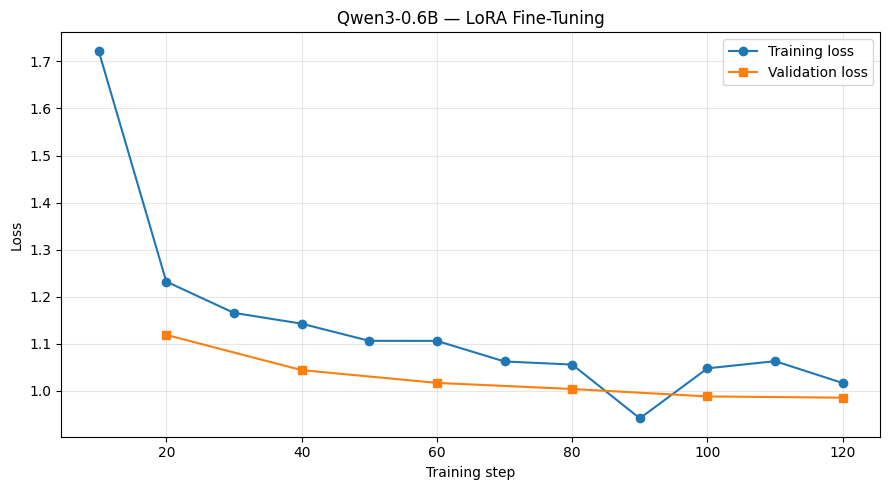


ТАБЛИЦЯ TRAINING / VALIDATION LOSS
Step    Training loss     Validation loss
20      1.2320            1.1188
40      1.1426            1.0439
60      1.1060            1.0167
80      1.0557            1.0037
100     1.0477            0.9880
120     1.0164            0.9853

Графік збережено: /content/drive/MyDrive/ai_systems/lab5/lora_stories/training_loss.png


In [16]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

from google.colab import drive

HISTORY_FILE = Path(
    "/content/drive/MyDrive/ai_systems/lab5/"
    "lora_stories/training_history.json"
)

# Підключаємо диск, якщо він відключений
if not HISTORY_FILE.exists():
    drive.mount("/content/drive")

assert HISTORY_FILE.exists(), "Журнал навчання не знайдено"

with open(HISTORY_FILE, encoding="utf-8") as f:
    history = json.load(f)

# Дані training loss
train_points = sorted(
    (row["step"], row["loss"])
    for row in history
    if "loss" in row and "step" in row
)

# Дані validation loss
val_points = sorted(
    (row["step"], row["eval_loss"])
    for row in history
    if "eval_loss" in row and "step" in row
)

assert train_points and val_points, "Дані loss відсутні"

train_steps, train_losses = zip(*train_points)
val_steps, val_losses = zip(*val_points)

# Побудова графіка
plt.figure(figsize=(9, 5))

plt.plot(
    train_steps,
    train_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    val_steps,
    val_losses,
    marker="s",
    label="Validation loss"
)

plt.title("Qwen3-0.6B — LoRA Fine-Tuning")
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Збереження графіка на Google Диск
GRAPH_FILE = HISTORY_FILE.parent / "training_loss.png"

plt.savefig(GRAPH_FILE, dpi=200, bbox_inches="tight")
plt.show()

# Таблиця на однакових кроках
train_by_step = dict(train_points)

print("\nТАБЛИЦЯ TRAINING / VALIDATION LOSS")
print(f"{'Step':<8}{'Training loss':<18}{'Validation loss'}")

for step, val_loss in val_points:
    train_loss = train_by_step.get(step)

    if train_loss is not None:
        print(f"{step:<8}{train_loss:<18.4f}{val_loss:.4f}")

print("\nГрафік збережено:", GRAPH_FILE)

**Аналіз графіка навчання**

Графік показує загальне зниження training loss протягом 120 кроків, хоча на окремих етапах спостерігаються незначні коливання. Validation loss стабільно зменшується з 1,1188 на 20-му кроці до 0,9853 на 120-му, що свідчить про покращення передбачення еталонних відповідей на валідаційних даних

Ознак перенавчання на графіку не виявлено, оскільки validation loss не починає зростати на тлі зменшення training loss. Водночас навчання охопило лише 0,064 епохи, тому остаточну ефективність донавчання необхідно перевірити на незалежній тестовій вибірці

Отже, процес донавчання проходив стабільно, а отримані результати не вказують на необхідність зміни гіперпараметрів через перенавчання

## **1.5. Порівняння моделі до та після донавчання**

### **Перевірка збережених результатів і моделі**

Перед порівнянням перевіримо збережені результати початкової моделі та донавчений адаптер LoRA. Переконаємося, що результати містять усі 100 тестових прикладів, а параметри оцінювання та промпт V1 збережені без змін

Це дозволить використати однакові умови тестування та об'єктивно оцінити вплив донавчання на якість літературного аналізу

In [17]:
import json
from pathlib import Path
from google.colab import drive

# Підключення Google Диска
drive.mount("/content/drive")

SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")

BASELINE_FILE = SAVE_DIR / "baseline_test_100.json"
PROMPTS_FILE = SAVE_DIR / "prompts_v1_v2.json"
TRAINING_FILE = SAVE_DIR / "lora_stories/training_summary.json"

ADAPTER_DIR = SAVE_DIR / "lora_stories/final_adapter"
ADAPTER_CONFIG = ADAPTER_DIR / "adapter_config.json"

# Перевірка наявності файлів
required_files = [
    BASELINE_FILE,
    PROMPTS_FILE,
    TRAINING_FILE,
    ADAPTER_CONFIG
]

for file in required_files:
    assert file.exists(), f"Файл не знайдено: {file}"

assert (
    (ADAPTER_DIR / "adapter_model.safetensors").exists()
    or (ADAPTER_DIR / "adapter_model.bin").exists()
), "Ваги LoRA-адаптера не знайдено"

# Завантаження попередніх результатів
with open(BASELINE_FILE, encoding="utf-8") as f:
    baseline_saved = json.load(f)

with open(PROMPTS_FILE, encoding="utf-8") as f:
    prompts_saved = json.load(f)

with open(TRAINING_FILE, encoding="utf-8") as f:
    training_saved = json.load(f)

with open(ADAPTER_CONFIG, encoding="utf-8") as f:
    adapter_saved = json.load(f)

baseline_items = baseline_saved["items"]
baseline_config = baseline_saved["config"]

# Перевірка параметрів
assert len(baseline_items) == 100
assert baseline_config["test_count"] == 100
assert baseline_config["seed"] == 42
assert baseline_config["prompt"] == "V1"

assert baseline_config["max_new_tokens"] == 450
assert baseline_config["do_sample"] is False

assert baseline_config["prompt_text"] == (
    prompts_saved["prompt_v1"]
)

assert baseline_config["model"] == "Qwen/Qwen3-0.6B"
assert training_saved["global_step"] == 120

# Перевірка ідентичності записів у збережених результатах
saved_hashes = baseline_config["story_hashes"]

assert len(saved_hashes) == 100
assert len(set(saved_hashes)) == 100

for i, item in enumerate(baseline_items):
    assert item["index"] == i
    assert item["story_hash"] == saved_hashes[i]

print("ПЕРЕВІРКА ЗАВЕРШЕНА УСПІШНО")

print("\nПОЧАТКОВА МОДЕЛЬ")
print("Модель:", baseline_config["model"])
print("Тестових прикладів:", len(baseline_items))
print("Промпт:", baseline_config["prompt"])
print("Seed:", baseline_config["seed"])

print("\nДОНАВЧЕНА МОДЕЛЬ")
print("Кроків навчання:", training_saved["global_step"])
print("LoRA r:", adapter_saved["r"])
print("LoRA alpha:", adapter_saved["lora_alpha"])
print("Адаптер:", ADAPTER_DIR)

print("\nУМОВИ ГЕНЕРАЦІЇ")
print("max_new_tokens:", baseline_config["max_new_tokens"])
print("do_sample:", baseline_config["do_sample"])

print("\nУсі необхідні файли знайдено")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ПЕРЕВІРКА ЗАВЕРШЕНА УСПІШНО

ПОЧАТКОВА МОДЕЛЬ
Модель: Qwen/Qwen3-0.6B
Тестових прикладів: 100
Промпт: V1
Seed: 42

ДОНАВЧЕНА МОДЕЛЬ
Кроків навчання: 120
LoRA r: 16
LoRA alpha: 32
Адаптер: /content/drive/MyDrive/ai_systems/lab5/lora_stories/final_adapter

УМОВИ ГЕНЕРАЦІЇ
max_new_tokens: 450
do_sample: False

Усі необхідні файли знайдено


### **Завантаження моделі з LoRA-адаптером**

Завантажимо початкову модель Qwen3-0.6B та підключимо збережений LoRA-адаптер, отриманий після 120 кроків донавчання

Підготуємо модель до генерації відповідей і перевіримо, що адаптер успішно завантажено. Для подальшого порівняння використаємо той самий промпт V1 і параметри генерації, що й під час оцінювання початкової моделі

In [18]:
import gc
import torch

from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

assert torch.cuda.is_available(), "Потрібен GPU T4"

# Звільняємо пам'ять від попереднього тренування
for name in ["trainer", "train_model", "model", "base_model"]:
    if name in globals():
        del globals()[name]

gc.collect()
torch.cuda.empty_cache()

# Відновлюємо параметри початкового тестування
MODEL_NAME = baseline_config["model"]
SYSTEM_PROMPT_V1 = baseline_config["prompt_text"]

# Завантаження токенізатора
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Завантаження початкової моделі
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto"
)

# Підключення збереженого LoRA-адаптера
model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_DIR),
    is_trainable=False
)

# Режим оцінювання
model.eval()

# Перевірка
print("ДОНАВЧЕНУ МОДЕЛЬ ЗАВАНТАЖЕНО")
print("Модель:", MODEL_NAME)
print("Пристрій:", next(model.parameters()).device)
print("Адаптери:", list(model.peft_config.keys()))
print("Промпт V1:", len(SYSTEM_PROMPT_V1), "символів")

print(
    "Використана пам'ять GPU:",
    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
)

print("\nМодель готова до тестування")

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

ДОНАВЧЕНУ МОДЕЛЬ ЗАВАНТАЖЕНО
Модель: Qwen/Qwen3-0.6B
Пристрій: cuda:0
Адаптери: ['default']
Промпт V1: 932 символів
Використана пам'ять GPU: 1.16 GB

Модель готова до тестування


### **Перевірка однакових тестових даних та параметрів генерації**

Перед повторним тестуванням відновимо ті самі 100 історій із тестової вибірки та перевіримо їхню відповідність збереженим результатам початкової моделі

Після перевірки виконаємо пробну генерацію для однієї історії, використовуючи незмінний промпт V1 і ті самі параметри генерації. Це дозволить переконатися в коректності порівняння до та після донавчання

In [19]:
import hashlib
import torch

# Потрібна тестова вибірка з розділу 1.2
assert "test_data" in globals(), (
    "Спочатку виконай комірки завантаження датасету "
    "та поділу вибірок із пункту 1.2"
)

# Відновлення тих самих 100 історій
N_TEST = baseline_config["test_count"]
test_sample = (
    test_data.shuffle(seed=baseline_config["seed"])
    .select(range(N_TEST))
)

def text_hash(text):
    return hashlib.sha256(
        text.encode("utf-8")
    ).hexdigest()

# Перевірка всіх історій та еталонних відповідей
fields = [
    "characters",
    "setting_time",
    "setting_place",
    "plot_conflict",
    "theme"
]

for i, example in enumerate(test_sample):
    assert text_hash(example["text"]) == (
        baseline_items[i]["story_hash"]
    ), f"Не збігається історія {i}"

    assert example["title"] == (
        baseline_items[i]["title"]
    ), f"Не збігається назва {i}"

    reference = {
        field: example[field] for field in fields
    }

    assert reference == baseline_items[i]["reference"], (
        f"Не збігається еталон {i}"
    )

print("Усі 100 тестових історій та еталони збігаються")

# Функція генерації з попередніми налаштуваннями
def generate_finetuned_answer(story):
    messages = [
        {
            "role": "system",
            "content": baseline_config["prompt_text"]
        },
        {
            "role": "user",
            "content": (
                "Analyze the following short story:\n\n"
                + story
            )
        }
    ]

    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted,
        return_tensors="pt"
    ).to(next(model.parameters()).device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=baseline_config["max_new_tokens"],
            do_sample=baseline_config["do_sample"],
            pad_token_id=tokenizer.eos_token_id
        )

    generated = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    return answer, int(inputs["input_ids"].shape[1])


# Пробна генерація на першій історії
example = test_sample[0]

new_answer, input_tokens = generate_finetuned_answer(
    example["text"]
)

assert input_tokens == baseline_items[0]["input_tokens"], (
    "Кількість вхідних токенів змінилася"
)

print("\nПРОБНЕ ПОРІВНЯННЯ")
print("Історія:", example["title"])
print("Вхідних токенів:", input_tokens)

print("\nДО ДОНАВЧАННЯ:")
print(baseline_items[0]["answer"])

print("\nПІСЛЯ ДОНАВЧАННЯ:")
print(new_answer)

Усі 100 тестових історій та еталони збігаються

ПРОБНЕ ПОРІВНЯННЯ
Історія: A Mother's Love
Вхідних токенів: 780

ДО ДОНАВЧАННЯ:
```json
{
  "characters": ["I", "JoyAnna"],
  "setting_time": "present tense",
  "setting_place": "home",
  "plot_conflict": "JoyAnna's ear infection and the stress of her health and family issues",
  "theme": "recovery, family, and finding peace"
}
```

ПІСЛЯ ДОНАВЧАННЯ:
{"characters":["The narrator (mom)","JoyAnna (child)","Dean (narrator's partner)"],"setting_time":"Contemporary/modern day","setting_place":"The narrator's home","plot_conflict":"The narrator is concerned about JoyAnna's ear infection and decides to call a doctor to get her antibiotics","theme":"The importance of family, love, and finding peace in the face of adversity"}


### **Оцінювання донавченої моделі на тестовій вибірці**

Оцінимо донавчену модель Qwen3-0.6B з адаптером LoRA на тих самих 100 тестових історіях, які використовувалися до донавчання

Для коректного порівняння збережемо промпт V1, параметри генерації та методику розрахунку метрик. Результати кожної історії автоматично зберігатимуться на Google Диску, щоб у разі завершення сесії Colab можна було продовжити оцінювання

In [21]:
!pip -q install rouge-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [22]:
import json
import os
import re
import numpy as np
import torch

from pathlib import Path
from rouge_score import rouge_scorer

# Перевірка готовності
assert len(test_sample) == 100
assert len(baseline_items) == 100
assert "model" in globals()
assert "generate_finetuned_answer" in globals()

model.eval()

target_fields = [
    "characters",
    "setting_time",
    "setting_place",
    "plot_conflict",
    "theme"
]

text_fields = [
    "setting_time",
    "setting_place",
    "plot_conflict",
    "theme"
]

scorer = rouge_scorer.RougeScorer(
    ["rougeL"],
    use_stemmer=True
)

# Ті самі функції оцінювання, що й у пункті 1.3
def parse_answer(answer):
    raw = answer.strip()

    try:
        return json.loads(raw), True, True
    except (json.JSONDecodeError, TypeError):
        pass

    match = re.fullmatch(
        r"```(?:json)?\s*(.*?)\s*```",
        raw,
        flags=re.IGNORECASE | re.DOTALL
    )

    if match:
        try:
            return json.loads(match.group(1)), False, True
        except json.JSONDecodeError:
            pass

    return None, False, False


def check_schema(parsed):
    return (
        isinstance(parsed, dict)
        and set(parsed) == set(target_fields)
        and isinstance(parsed.get("characters"), list)
        and all(isinstance(x, str) for x in parsed["characters"])
        and all(
            isinstance(parsed.get(field), str)
            for field in target_fields
            if field != "characters"
        )
    )


def character_key(value):
    text = str(value).lower().strip()
    text = re.sub(r"\([^)]*\)", "", text).strip()
    text = re.sub(r"^(the|a|an)\s+", "", text)

    if text in {"i", "me", "narrator", "unnamed narrator"}:
        return "narrator"

    return " ".join(text.split())


def characters_f1(reference, prediction):
    ref = {character_key(x) for x in reference}
    pred = {character_key(x) for x in prediction}

    if not ref and not pred:
        return 1.0

    if not ref or not pred:
        return 0.0

    correct = len(ref & pred)

    precision = correct / len(pred)
    recall = correct / len(ref)

    if precision + recall == 0:
        return 0.0

    return 2 * precision * recall / (precision + recall)


# Файл для збереження результатів
RESULT_FILE = (
    SAVE_DIR / "lora_stories" / "finetuned_test_100.json"
)

# Фіксуємо умови експерименту
comparison_config = {
    "baseline_config": baseline_config,
    "stage": "after_lora",
    "adapter_path": str(ADAPTER_DIR),
    "training_steps": training_saved["global_step"]
}

# Відновлення після можливого відключення Colab
if RESULT_FILE.exists():
    saved = json.loads(
        RESULT_FILE.read_text(encoding="utf-8")
    )

    assert saved["config"] == comparison_config, (
        "Параметри експерименту змінилися"
    )

    finetuned_items = saved["items"]
else:
    finetuned_items = []

assert len(finetuned_items) <= 100

for i, item in enumerate(finetuned_items):
    assert item["index"] == i
    assert item["story_hash"] == baseline_items[i]["story_hash"]

print("Уже оцінено:", len(finetuned_items))
print("Усього потрібно:", 100)

# Тестування
for i in range(len(finetuned_items), 100):

    example = test_sample[i]

    answer, input_tokens = generate_finetuned_answer(
        example["text"]
    )

    # Незмінність вхідної послідовності
    assert input_tokens == baseline_items[i]["input_tokens"]

    parsed, clean_json, valid_json = parse_answer(answer)
    valid_schema = check_schema(parsed)

    char_f1 = 0.0
    rouge_scores = {
        field: 0.0 for field in text_fields
    }

    if valid_schema:
        char_f1 = characters_f1(
            example["characters"] or [],
            parsed["characters"]
        )

        for field in text_fields:
            rouge_scores[field] = scorer.score(
                str(example[field] or ""),
                parsed[field]
            )["rougeL"].fmeasure

    finetuned_items.append({
        "index": i,
        "title": example["title"],
        "story_hash": baseline_items[i]["story_hash"],
        "input_tokens": input_tokens,
        "reference": baseline_items[i]["reference"],
        "answer": answer,
        "clean_json": bool(clean_json),
        "valid_json": bool(valid_json),
        "valid_schema": bool(valid_schema),
        "characters_f1": float(char_f1),
        "rouge_l": float(np.mean(
            list(rouge_scores.values())
        )),
        "rouge_by_field": rouge_scores
    })

    # Збереження після кожної історії
    temp_file = RESULT_FILE.with_suffix(".tmp")

    with open(temp_file, "w", encoding="utf-8") as f:
        json.dump(
            {
                "config": comparison_config,
                "items": finetuned_items
            },
            f,
            ensure_ascii=False,
            indent=2
        )

    os.replace(temp_file, RESULT_FILE)

    if (i + 1) % 5 == 0:
        print(f"Оцінено {i + 1}/100")


# Підсумкові метрики
metric_keys = {
    "Clean JSON Rate": "clean_json",
    "Valid JSON Rate": "valid_json",
    "Schema Accuracy": "valid_schema",
    "Characters F1": "characters_f1",
    "ROUGE-L F1": "rouge_l"
}

print("\nПОРІВНЯННЯ ДО ТА ПІСЛЯ ДОНАВЧАННЯ")
print(
    f"{'Метрика':<22}"
    f"{'До':>12}"
    f"{'Після':>12}"
    f"{'Зміна, в.п.':>16}"
)

for name, key in metric_keys.items():
    before = np.mean([
        item[key] for item in baseline_items
    ])

    after = np.mean([
        item[key] for item in finetuned_items
    ])

    difference = (after - before) * 100

    print(
        f"{name:<22}"
        f"{before * 100:>11.2f}%"
        f"{after * 100:>11.2f}%"
        f"{difference:>+15.2f}"
    )

print("\nРезультати збережено:", RESULT_FILE)

Уже оцінено: 0
Усього потрібно: 100
Оцінено 5/100
Оцінено 10/100
Оцінено 15/100
Оцінено 20/100
Оцінено 25/100
Оцінено 30/100
Оцінено 35/100
Оцінено 40/100
Оцінено 45/100
Оцінено 50/100
Оцінено 55/100
Оцінено 60/100
Оцінено 65/100
Оцінено 70/100
Оцінено 75/100
Оцінено 80/100
Оцінено 85/100
Оцінено 90/100
Оцінено 95/100
Оцінено 100/100

ПОРІВНЯННЯ ДО ТА ПІСЛЯ ДОНАВЧАННЯ
Метрика                         До       Після     Зміна, в.п.
Clean JSON Rate              0.00%     100.00%        +100.00
Valid JSON Rate            100.00%     100.00%          +0.00
Schema Accuracy            100.00%     100.00%          +0.00
Characters F1               61.20%      65.81%          +4.62
ROUGE-L F1                  26.29%      37.63%         +11.33

Результати збережено: /content/drive/MyDrive/ai_systems/lab5/lora_stories/finetuned_test_100.json


### **Аналіз результатів порівняння**

Порівняння початкової та донавченої Qwen3-0.6B проведено на тих самих 100 тестових історіях із незмінним промптом V1 та однаковими параметрами генерації

Після донавчання Clean JSON Rate зріс із 0% до 100%, Characters F1 — із 61,20% до 65,81%, а ROUGE-L F1 — із 26,29% до 37,63%. Показники Valid JSON Rate та Schema Accuracy залишилися на рівні 100%

Результати свідчать про покращення дотримання формату JSON, розпізнавання персонажів і текстової відповідності еталонним літературним характеристикам. Водночас для оцінювання змістової правильності необхідно окремо проаналізувати відповіді донавченої моделі та випадки, у яких вона припускається помилок

### **Порівняння відповідей та аналіз помилок**

Для якісного аналізу порівняємо відповіді початкової та донавченої моделей на восьми однакових тестових історіях

Додатково визначимо приклади з найнижчими значеннями Characters F1 та ROUGE-L F1, а також історії, на яких після донавчання оцінки погіршилися. Порівняємо відповіді з еталонами, щоб з'ясувати причини помилок

In [23]:
import json
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/ai_systems/lab5")

# Завантажуємо обидва збережені набори результатів
with open(
    SAVE_DIR / "baseline_test_100.json",
    encoding="utf-8"
) as f:
    before_items = json.load(f)["items"]

with open(
    SAVE_DIR / "lora_stories/finetuned_test_100.json",
    encoding="utf-8"
) as f:
    after_items = json.load(f)["items"]

assert len(before_items) == len(after_items) == 100

for before, after in zip(before_items, after_items):
    assert before["story_hash"] == after["story_hash"]

# Порівняння восьми історій із пункту 1.3
print("ПОРІВНЯННЯ ПЕРШИХ 8 ІСТОРІЙ")

for i in range(8):
    before = before_items[i]
    after = after_items[i]

    print(f"\n{i + 1}. {before['title']}")
    print(
        f"Characters F1: "
        f"{before['characters_f1'] * 100:.2f}% → "
        f"{after['characters_f1'] * 100:.2f}%"
    )
    print(
        f"ROUGE-L F1: "
        f"{before['rouge_l'] * 100:.2f}% → "
        f"{after['rouge_l'] * 100:.2f}%"
    )

# Історії з найнижчими оцінками після LoRA
worst = sorted(
    range(100),
    key=lambda i: (
        after_items[i]["characters_f1"]
        + after_items[i]["rouge_l"]
    )
)[:5]

print("\n5 ІСТОРІЙ З НАЙНИЖЧИМИ ОЦІНКАМИ")

for i in worst:
    item = after_items[i]
    print(
        f"{i + 1}. {item['title']} | "
        f"Characters F1: {item['characters_f1'] * 100:.2f}% | "
        f"ROUGE-L F1: {item['rouge_l'] * 100:.2f}%"
    )

# Історії з найбільшим зниженням оцінок
def total_score(item):
    return item["characters_f1"] + item["rouge_l"]

declines = sorted(
    range(100),
    key=lambda i: (
        total_score(after_items[i])
        - total_score(before_items[i])
    )
)[:5]

print("\n5 ІСТОРІЙ ІЗ НАЙБІЛЬШИМ ПОГІРШЕННЯМ")

for i in declines:
    before = before_items[i]
    after = after_items[i]

    change = (
        total_score(after) - total_score(before)
    ) * 50

    print(
        f"{i + 1}. {after['title']} | "
        f"Зміна середньої оцінки: {change:+.2f} в. п."
    )

# Детальний перегляд трьох проблемних прикладів
print("\nДЕТАЛЬНЕ ПОРІВНЯННЯ")

for i in worst[:3]:
    before = before_items[i]
    after = after_items[i]

    print("\n" + "=" * 65)
    print(f"ІСТОРІЯ {i + 1}: {after['title']}")

    print("\nЕТАЛОН:")
    print(json.dumps(
        after["reference"],
        ensure_ascii=False,
        indent=2
    ))

    print("\nДО ДОНАВЧАННЯ:")
    print(before["answer"])

    print("\nПІСЛЯ ДОНАВЧАННЯ:")
    print(after["answer"])

    print("\nОЦІНКИ ПІСЛЯ LoRA")
    print(
        f"Characters F1: "
        f"{after['characters_f1'] * 100:.2f}%"
    )
    print(
        f"ROUGE-L F1: "
        f"{after['rouge_l'] * 100:.2f}%"
    )

ПОРІВНЯННЯ ПЕРШИХ 8 ІСТОРІЙ

1. A Mother's Love
Characters F1: 100.00% → 80.00%
ROUGE-L F1: 16.13% → 59.64%

2. The Oak Ridge Years
Characters F1: 100.00% → 100.00%
ROUGE-L F1: 31.31% → 37.62%

3. Conquering the Depths
Characters F1: 66.67% → 33.33%
ROUGE-L F1: 50.54% → 21.67%

4. A Colorful Face
Characters F1: 80.00% → 40.00%
ROUGE-L F1: 24.23% → 32.23%

5. A Day of Connection
Characters F1: 80.00% → 66.67%
ROUGE-L F1: 20.50% → 52.73%

6. Relapse and Renewal
Characters F1: 50.00% → 80.00%
ROUGE-L F1: 26.85% → 41.32%

7. Unwanted Thoughts
Characters F1: 100.00% → 100.00%
ROUGE-L F1: 28.61% → 26.15%

8. The Weight of What Could Have Been
Characters F1: 40.00% → 40.00%
ROUGE-L F1: 17.50% → 32.49%

5 ІСТОРІЙ З НАЙНИЖЧИМИ ОЦІНКАМИ
56. The Catmage's Plan | Characters F1: 0.00% | ROUGE-L F1: 22.35%
50. Realfaery | Characters F1: 0.00% | ROUGE-L F1: 24.93%
24. The Band | Characters F1: 0.00% | ROUGE-L F1: 25.77%
77. A Different Beast | Characters F1: 0.00% | ROUGE-L F1: 32.73%
18. I was a tod

### **Аналіз помилок донавченої моделі**

Аналіз окремих тестових історій показав, що попри загальне покращення метрик донавчена модель не завжди правильно визначає літературні характеристики

У *The Catmage's Plan* модель продублювала одного персонажа, неточно визначила час подій і відхилилася від основної теми. У *Realfaery* до списку персонажів потрапили назва організації та поняття, які не є окремими дійовими особами. У *The Band* модель пропустила другорядних персонажів і неповно описала сюжетний конфлікт

Окремим обмеженням є Characters F1, оскільки метрика порівнює нормалізовані текстові позначення персонажів і не завжди враховує різні способи запису того самого імені. Тому нульове значення F1 в окремих прикладах не обов'язково свідчить про повну відсутність правильно визначених персонажів

Тож донавчання покращило середні результати, але не усунуло всіх змістових помилок. Для повнішого оцінювання необхідно враховувати як числові метрики, так і якісний аналіз відповідей

### **Детальний аналіз випадків погіршення**

Додатково розглянемо історії, на яких після донавчання спостерігається найбільше зниження оцінок. Порівняємо оригінальні тексти, еталонні характеристики та відповіді обох моделей, щоб відокремити фактичні помилки літературного аналізу від обмежень автоматичних метрик

In [24]:
import json

# Дві історії з найбільшим погіршенням оцінок
selected_indices = [43, 2]

for i in selected_indices:
    before = before_items[i]
    after = after_items[i]
    story = test_sample[i]

    assert before["story_hash"] == after["story_hash"]
    assert before["title"] == story["title"]

    print("\n" + "=" * 70)
    print("ІСТОРІЯ:", story["title"])

    print("\nОРИГІНАЛЬНИЙ ТЕКСТ:")
    print(story["text"])

    print("\nЕТАЛОННА ВІДПОВІДЬ:")
    print(json.dumps(
        before["reference"],
        ensure_ascii=False,
        indent=2
    ))

    print("\nДО ДОНАВЧАННЯ:")
    print(before["answer"])

    print("\nПІСЛЯ ДОНАВЧАННЯ:")
    print(after["answer"])

    print("\nПОРІВНЯННЯ МЕТРИК:")
    print(
        f"Characters F1: "
        f"{before['characters_f1'] * 100:.2f}% → "
        f"{after['characters_f1'] * 100:.2f}%"
    )
    print(
        f"ROUGE-L F1: "
        f"{before['rouge_l'] * 100:.2f}% → "
        f"{after['rouge_l'] * 100:.2f}%"
    )


ІСТОРІЯ: Fair Share

ОРИГІНАЛЬНИЙ ТЕКСТ:
The city of San Francisco in the 1970s and 80s was a place of liberation and self-discovery, a place where Steve Abbott found himself among like-minded individuals who embraced his identity as a gay man. It was a place where he could be free, where he could live openly and honestly without fear of judgment or persecution.

As Steve settled into his new life, he became a part of the vibrant gay community in the city. He met new friends, formed connections, and found solace in the camaraderie of those who shared his experiences. He began to build a life for himself, one that was filled with love, laughter, and a sense of belonging.

But Steve's life was not without its challenges. As a single father to Alysia, he faced the daunting task of raising a young child on his own. He juggled work and parenting, often relying on the help of friends and neighbors to care for Alysia while he was out. Despite the difficulties, Steve was determined to provide

### **Аналіз випадків погіршення після донавчання**

У результаті додаткового аналізу виявлено, що донавчання не забезпечує покращення на кожній окремій історії

У *Fair Share* Characters F1 знизився зі 100% до 33,33%, а ROUGE-L F1 з 63,36% до 52,69%. Після донавчання модель додала узагальнену групу другорядних осіб та повторно вказала головного героя. Водночас сюжетний конфлікт описано детальніше, тому зниження автоматичних метрик не означає погіршення всіх складових аналізу

У *Conquering the Depths* Characters F1 знизився з 66,67% до 33,33%, а ROUGE-L F1 з 50,54% до 21,67%. Донавчена модель правильно виявила головну героїню та плавчиню, яка їй допомогла, але помилково визначила частини тіла плавчині як окремих персонажів

Таким чином, основними виявленими недоліками є дублювання персонажів, включення до їхнього списку об'єктів або груп осіб і неточне визначення другорядних героїв. Також оцінювання залежить від формулювань еталонних відповідей, що обмежує інтерпретацію Characters F1 та ROUGE-L F1

Попри ці помилки, загальні результати на 100 тестових історіях підтверджують покращення середніх показників після донавчання

### **Перевірка загальних можливостей моделі після донавчання**

Перевіримо, чи зберегла модель здатність виконувати загальні завдання після спеціалізованого донавчання. Для цього порівняємо відповіді початкової та донавченої моделей на п'яти запитах, не пов'язаних із літературним аналізом

Використаємо однакові запити, нейтральний системний промпт і параметри генерації. Відповіді порівняємо за правильністю, повнотою та дотриманням інструкцій

In [25]:
import json
import torch
from pathlib import Path

assert "model" in globals(), "Спочатку завантаж модель із LoRA"
assert torch.cuda.is_available(), "Потрібен GPU"

model.eval()

# Загальні завдання поза літературним аналізом
general_tests = [
    {
        "category": "Arithmetic",
        "prompt": "Calculate 17 * 24. Return only the number."
    },
    {
        "category": "Translation",
        "prompt": (
            "Translate into English: "
            "'На вулиці холодно, але завтра потеплішає.' "
            "Return only the translation."
        )
    },
    {
        "category": "Explanation",
        "prompt": (
            "Explain what computer RAM is "
            "in two simple sentences."
        )
    },
    {
        "category": "Programming",
        "prompt": (
            "Write a Python function is_even(n) "
            "that returns True if n is even and False otherwise. "
            "Return only the code."
        )
    },
    {
        "category": "Logic",
        "prompt": (
            "All cats are mammals. Some mammals live in water. "
            "Does it necessarily follow that some cats live "
            "in water? Answer yes or no and explain briefly."
        )
    }
]

GENERAL_SYSTEM = (
    "You are a helpful assistant. "
    "Answer accurately and follow the user's instructions."
)

OOD_FILE = (
    SAVE_DIR / "lora_stories" / "general_queries_comparison.json"
)

# Однакова генерація для обох моделей
def generate_general_answer(prompt):
    messages = [
        {"role": "system", "content": GENERAL_SYSTEM},
        {"role": "user", "content": prompt}
    ]

    formatted = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    inputs = tokenizer(
        formatted,
        return_tensors="pt"
    ).to(next(model.parameters()).device)

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=200,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = outputs[0][inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()


# Відновлення збережених результатів
if OOD_FILE.exists():
    results = json.loads(
        OOD_FILE.read_text(encoding="utf-8")
    )
else:
    results = []

for i, test in enumerate(general_tests):
    if i < len(results):
        assert results[i]["category"] == test["category"]
        assert results[i]["prompt"] == test["prompt"]
        continue

    # Початкова модель: LoRA вимкнено
    with model.disable_adapter():
        before = generate_general_answer(test["prompt"])

    # Донавчена модель: LoRA увімкнено
    after = generate_general_answer(test["prompt"])

    results.append({
        "category": test["category"],
        "prompt": test["prompt"],
        "before": before,
        "after": after
    })

    # Збереження результатів
    with open(OOD_FILE, "w", encoding="utf-8") as f:
        json.dump(
            results,
            f,
            ensure_ascii=False,
            indent=2
        )

    print(f"Перевірено {i + 1}/{len(general_tests)}")


# Порівняння відповідей
print("\nПОРІВНЯННЯ ЗАГАЛЬНИХ МОЖЛИВОСТЕЙ")

for i, result in enumerate(results, 1):
    print("\n" + "=" * 65)
    print(f"ТЕСТ {i}: {result['category']}")

    print("\nЗАПИТ:")
    print(result["prompt"])

    print("\nДО ДОНАВЧАННЯ:")
    print(result["before"])

    print("\nПІСЛЯ ДОНАВЧАННЯ:")
    print(result["after"])

print("\nРезультати збережено:", OOD_FILE)

Перевірено 1/5
Перевірено 2/5
Перевірено 3/5
Перевірено 4/5
Перевірено 5/5

ПОРІВНЯННЯ ЗАГАЛЬНИХ МОЖЛИВОСТЕЙ

ТЕСТ 1: Arithmetic

ЗАПИТ:
Calculate 17 * 24. Return only the number.

ДО ДОНАВЧАННЯ:
368

ПІСЛЯ ДОНАВЧАННЯ:
17 * 24 = 408

ТЕСТ 2: Translation

ЗАПИТ:
Translate into English: 'На вулиці холодно, але завтра потеплішає.' Return only the translation.

ДО ДОНАВЧАННЯ:
The street is cold, but tomorrow will be warm.

ПІСЛЯ ДОНАВЧАННЯ:
"Outside the street is cold, but tomorrow will be warm."

ТЕСТ 3: Explanation

ЗАПИТ:
Explain what computer RAM is in two simple sentences.

ДО ДОНАВЧАННЯ:
Computer RAM is a type of memory used to store data temporarily while the computer is running. It helps keep the computer running smoothly by storing information that needs to be accessed quickly.

ПІСЛЯ ДОНАВЧАННЯ:
Computer RAM is a type of memory used to store and retrieve data and instructions that are needed to run a computer program. It is used to store the program's instructions and data, allow

### **Аналіз загальних можливостей моделі**

Для перевірки загальних можливостей моделі проведено порівняння на п'яти запитах поза задачею літературного аналізу: арифметика, переклад, пояснення терміна, програмування та логічний висновок

Після донавчання модель правильно виконала арифметичне завдання, з яким раніше помилилася. Якість пояснення поняття RAM і написання Python-функції загалом збереглася. Водночас переклад залишився неприродним, а в логічному завданні обидві версії моделі зробили однаковий неправильний висновок

Також після донавчання в окремих відповідях спостерігалося гірше дотримання інструкцій щодо формату, зокрема додавання пояснення до числової відповіді та зайвих прикладів до програмного коду

Отже, перевірка не виявила повної втрати загальних можливостей моделі, проте окремі недоліки збереглися або посилилися. Оскільки експеримент охоплював лише п'ять запитів, його результати не дозволяють зробити однозначний висновок про зміни загальної якості моделі

### **Висновок за результатами порівняння**

Порівняння на 100 однакових тестових історіях показало, що донавчання Qwen3-0.6B методом LoRA покращило результати спеціалізованої задачі. Clean JSON Rate зріс із 0% до 100%, Characters F1 із 61,20% до 65,81%, а ROUGE-L F1 із 26,29% до 37,63%. Valid JSON Rate та Schema Accuracy залишилися на рівні 100%

Аналіз окремих історій показав, що модель усе ще може дублювати персонажів, помилково визначати об'єкти як дійових осіб та неточно формулювати сюжетний конфлікт. Крім того, автоматичні метрики не завжди відображають змістову правильність відповідей через відмінності у формулюваннях

Перевірка на п'яти загальних запитах показала неоднозначні результати: окремі відповіді покращилися, інші залишилися помилковими або стали менш точними за форматом

Таким чином, донавчання виявилося ефективним для покращення формату та текстової відповідності літературних характеристик еталонам, але не усунуло всіх помилок і не гарантує покращення загальних можливостей моделі

## **Загальний висновок до лабораторної роботи**

У ході лабораторної роботи було реалізовано повний цикл донавчання мовної моделі для автоматичного аналізу коротких англомовних історій. Для виконання задачі обрано модель Qwen3-0.6B та датасет agentlans/stories-elements. Підготовлено навчальну, валідаційну й тестову вибірки, визначено структуру вихідних даних у форматі JSON та підібрано промпт для початкового оцінювання моделі

Донавчання проведено методом SFT із використанням LoRA в середовищі Google Colab із GPU T4. За 120 кроків навчання модель продемонструвала покращення результатів на фіксованому наборі зі 100 тестових історій: Clean JSON Rate зріс із 0% до 100%, Characters F1 із 61,20% до 65,81%, а ROUGE-L F1 із 26,29% до 37,63%

Порівняння відповідей показало, що донавчання підвищило стабільність формату та текстову відповідність літературних характеристик еталонним даним. Водночас виявлено окремі помилки у визначенні персонажів і сюжетних елементів. Додаткова перевірка на загальних запитах засвідчила, що покращення спеціалізованої задачі не гарантує аналогічного покращення інших можливостей моделі

Таким чином, поставлену задачу виконано та експериментально підтверджено доцільність використання LoRA для адаптації компактної мовної моделі до структурованого літературного аналізу. Отримані результати також показали важливість незалежного тестування, аналізу помилок і врахування обмежень автоматичних метрик під час оцінювання якості донавчених моделей

## **Додаткове завдання. Публікація LoRA-адаптера на Hugging Face**

LoRA-адаптер моделі Qwen3-0.6B, отриманий після 120 кроків донавчання, опубліковано на Hugging Face. Репозиторій містить ваги та конфігурацію адаптера, опис задачі, параметри навчання й результати оцінювання.

**Посилання на адаптер:** https://huggingface.co/ipz231msye/qwen3-0.6b-story-elements-lora